# AI Anxiety Map

This notebook analyzes aggregated GDELT location-theme interactions before
and after the widespread adoption of generative AI.

# Imports

In [81]:
from __future__ import annotations

import gc
from itertools import combinations
import os
from pathlib import Path

# os.environ.setdefault("XDG_CACHE_HOME", "/tmp")
# os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib-cache")
# Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
import networkx as nx
import numpy as np
import pandas as pd
import plotly.express as px
import pycountry
import pydeck as pdk
import seaborn as sns
from scipy.stats import ttest_ind

from dateutil.relativedelta import relativedelta

# Parameters

In [ ]:
STUDY_START = pd.Timestamp("2021-01-01")
AI_CUTOFF = pd.Timestamp("2023-01-01")
STUDY_END = pd.Timestamp("2024-12-31")

# For Testing
# STUDY_START = pd.Timestamp("2022-12-01")
# AI_CUTOFF = pd.Timestamp("2023-01-01")
# STUDY_END = pd.Timestamp("2023-02-01")

In [83]:
parts = []

duration = relativedelta(STUDY_END, STUDY_START)
if duration.years:
    parts.append(f"{duration.years} years")
if duration.months:
    parts.append(f"{duration.months} months")
if duration.days:
    parts.append(f"{duration.days} days")

print(f"Analyzing {', '.join(parts)}.")

Analyzing 2 months.


In [84]:
TOP_N = 15
TOP_COMMUNITIES_TO_PLOT = 20
MIN_INTERACTIONS_PER_COMMUNITY = 50
MAX_GRAPH_EDGES = 120
MIN_SIMILARITY = 0.35
WEIGHT_COLUMN = "interaction_count"

TONE_COLUMNS = [
    "tone_avg",
    "positive_score_avg",
    "negative_score_avg",
    "polarity_avg",
]
ANXIETY_COLUMNS = [
    "liwc_anxiety_avg",
    "wordnet_anxiety_avg",
    "wordnet_fear_avg",
    "lm_uncertainty_avg",
]
OPPORTUNITY_COLUMNS = [
    "wordnet_hope_avg",
    "wordnet_optimism_avg",
]
FEELING_COLUMNS = [
    "liwc_anger_avg",
    "liwc_anxiety_avg",
    "lm_uncertainty_avg",
    "wordnet_anger_avg",
    "wordnet_anxiety_avg",
    "wordnet_fear_avg",
    "wordnet_hope_avg",
    "wordnet_optimism_avg",
    "wordnet_feeling_avg",
]
DOMINANT_FEELING_COUNT_COLUMNS = [
    "count_anger",
    "count_anxiety",
    "count_fear",
    "count_hope",
    "count_optimism",
    "count_uncertainty",
    "count_unknown",
]
ANALYSIS_COLUMNS = [
    *TONE_COLUMNS,
    *FEELING_COLUMNS,
    "anxiety_score",
    "opportunity_score",
    "ai_anxiety_index",
]
LOAD_COLUMNS = [
    "location_type",
    "location_name",
    "location_country_code",
    "location_admin1_code",
    "start_date",
    "end_date",
    "article_count",
    "interaction_count",
    *FEELING_COLUMNS,
]

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update(
    {
        "axes.titlesize": 18,
        "axes.labelsize": 15,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "figure.titlesize": 20,
    }
)
pd.options.display.float_format = "{:,.3f}".format

# Input & Output Paths

In [85]:
def find_project_dir(start_dir: Path) -> Path:
    """Find the Project directory from common launch locations.

    Args:
        start_dir: Directory from which the notebook or script was launched.

    Returns:
        Project directory containing the data, result, and src folders.

    Raises:
        FileNotFoundError: If the Project directory cannot be found.
    """

    resolved_start = start_dir.resolve()
    candidates = [
        resolved_start,
        resolved_start / "Project",
        resolved_start.parent,
        resolved_start.parent / "Project",
    ]
    for candidate in candidates:
        if (candidate / "data").is_dir() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the Project directory.")

In [86]:
PROJECT_DIR = find_project_dir(Path.cwd())
DATA_DIR = PROJECT_DIR / "data" / "aggregated"
RESULT_DIR = PROJECT_DIR / "results" / f"start_{STUDY_START:%Y-%m-%d}_cutoff_{AI_CUTOFF:%Y-%m-%d}_end_{STUDY_END:%Y-%m-%d}"
RESULT_DIR.mkdir(parents=True, exist_ok=True)


print(f"Project directory: {PROJECT_DIR}")
print(f"Aggregated data directory: {DATA_DIR}")
print(f"Result directory: {RESULT_DIR}")

Project directory: /home/amitner/Data-Mining-Assignments/Project
Aggregated data directory: /home/amitner/Data-Mining-Assignments/Project/data/aggregated
Result directory: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01


## DataFrame Export

In [87]:
def save_dataframe_formats(
    dataframe: pd.DataFrame,
    file_stem: str,
    result_dir: Path,
) -> None:
    """Save an analysis DataFrame in CSV and LaTeX formats.

    Args:
        dataframe: Analysis table to export.
        file_stem: Output filename without an extension.
        result_dir: Directory in which to save both files.
    """

    result_dir.mkdir(parents=True, exist_ok=True)
    csv_path = result_dir / f"{file_stem}.csv"
    latex_path = result_dir / f"{file_stem}.tex"
    dataframe.to_csv(csv_path, index=False)
    dataframe.to_latex(
        latex_path,
        index=False,
        escape=True,
        float_format="{:,.3f}".format,
    )
    print(f"Saved DataFrame: {csv_path}")
    print(f"Saved DataFrame: {latex_path}")

# Load Data

In [88]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd


def plot_gdelt_data_timeline(
    df: pd.DataFrame,
    study_start: pd.Timestamp = STUDY_START,
    study_end: pd.Timestamp = STUDY_END,
) -> None:
    """Plot the available date coverage for each loaded GDELT dataset.

    Args:
        df: Combined GDELT aggregate data containing dataset, start_date,
            and end_date columns.
        study_start: Beginning of the study period.
        study_end: End of the study period.
    """
    required_columns = {"dataset", "start_date", "end_date"}
    missing_columns = required_columns.difference(df.columns)

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    timeline = (
        df[["dataset", "start_date", "end_date"]]
        .drop_duplicates()
        .sort_values(["dataset", "start_date", "end_date"])
    )

    datasets = timeline["dataset"].unique()

    fig, ax = plt.subplots(
        figsize=(14, max(4, len(datasets) * 0.55))
    )

    for y_position, dataset in enumerate(datasets):
        dataset_periods = timeline.loc[timeline["dataset"] == dataset]

        for period in dataset_periods.itertuples(index=False):
            start_date = pd.Timestamp(period.start_date)
            end_date = pd.Timestamp(period.end_date)

            ax.barh(
                y=y_position,
                width=end_date - start_date,
                left=start_date,
                height=0.65,
            )

    ax.set_xlim(pd.Timestamp(study_start), pd.Timestamp(study_end))
    ax.set_yticks(range(len(datasets)))
    ax.set_yticklabels(datasets)

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

    ax.set_title("Loaded GDELT Data Coverage")
    ax.set_xlabel("Date")
    ax.set_ylabel("Dataset")
    ax.grid(axis="x", alpha=0.3)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
    plt.close(fig)


def dataset_name(path: Path) -> str:
    """Create a readable dataset identifier from an aggregate filename.

    Args:
        path: Aggregate parquet path.

    Returns:
        Filename stem without a current or legacy GDELT prefix.
    """

    name = path.stem
    for prefix in ("gdelt_location_theme_", "gdelt_"):
        if name.startswith(prefix):
            return name.removeprefix(prefix)
    return name



In [89]:
def load_aggregated_gdelt_data(data_dir: Path) -> pd.DataFrame:
    """Load current and legacy aggregate parquet files.

    Args:
        data_dir: Directory containing final aggregate parquet files.

    Returns:
        Combined GDELT aggregates restricted to the study dates.

    Raises:
        FileNotFoundError: If no aggregate parquet files are available.
    """

    parquet_paths = sorted(data_dir.glob("gdelt_*.parquet"))
    if not parquet_paths:
        raise FileNotFoundError(f"No aggregate parquet files found in {data_dir}")

    frames = []
    filters = [
        ("start_date", ">=", STUDY_START.date()),
        ("start_date", "<=", STUDY_END.date()),
    ]
    for parquet_path in parquet_paths:
        frame = pd.read_parquet(
            parquet_path,
            columns=LOAD_COLUMNS,
            filters=filters,
            dtype_backend="pyarrow",
        )
        print(f"[load_aggregated_gdelt_data] Loading {parquet_path.name} with {len(frame):,} rows and {len(frame.columns)} columns")
        frame[FEELING_COLUMNS] = frame[FEELING_COLUMNS].astype("float32")
        frame["dataset"] = dataset_name(parquet_path)
        frames.append(frame)

    print(f"[load_aggregated_gdelt_data] concatenating {len(frames):,} frames.")
    df = pd.concat(frames, ignore_index=True)
    del frames, frame
    gc.collect()
    df["start_date"] = pd.to_datetime(df["start_date"])
    df["end_date"] = pd.to_datetime(df["end_date"])


    columns_text = "\n".join(
        f"  {index:>2}. {column:<30} {str(df[column].dtype)}"
        for index, column in enumerate(df.columns, start=1)
    )

    print(
        f"\nLoaded {len(df):,} aggregate rows "
        f"from {df['dataset'].nunique():,} files.\n"
        f"DataFrame shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns\n"
        f"DataFrame columns and types:\n{columns_text}"
    )

    return df

In [90]:
df = load_aggregated_gdelt_data(DATA_DIR)

[load_aggregated_gdelt_data] Loading gdelt_20210101_20210301_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20210501_20210701_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20210701_20210901_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20210901_20211101_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20211101_20220101_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20220101_20220301_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20220301_20220501_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20220501_20220701_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20220701_20220901_7D.parquet with 0 rows and 17 columns
[load_aggregated_gdelt_data] Loading gdelt_20220901_20221101_7D.parquet with 0 rows and 17 columns
[load_aggr

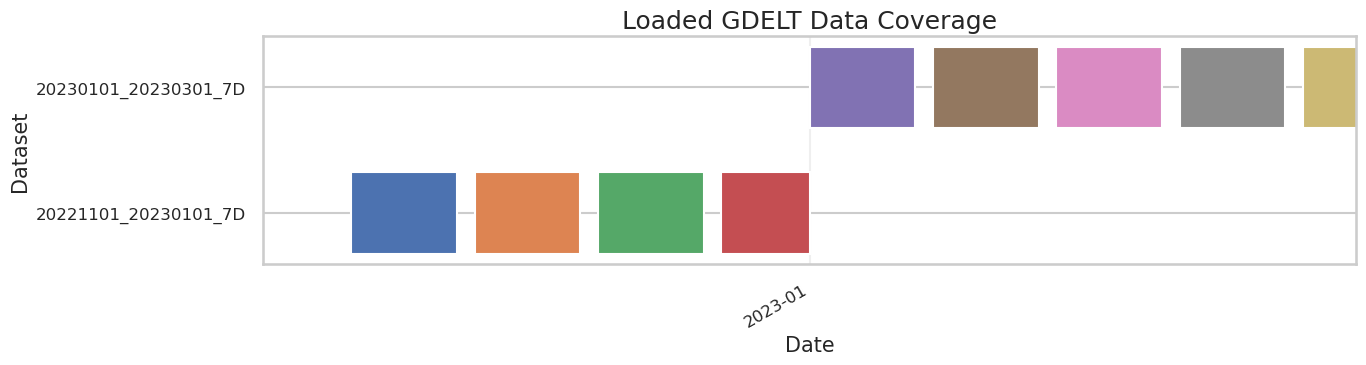

In [91]:
plot_gdelt_data_timeline(df)

# Global Analysis

## Analysis

In [92]:
def add_analysis_columns(
    df: pd.DataFrame,
) -> pd.DataFrame:
    """Add period and emotional-score fields in place.

    Args:
        df: Aggregated GDELT rows to enrich in place.

    Returns:
        The same DataFrame with the analysis columns added.
    """

    enriched_df = df
    # Before\after AI cutoff
    enriched_df["period"] = "after_ai"
    enriched_df.loc[enriched_df["start_date"] < AI_CUTOFF, "period"] = "before_ai"
    enriched_df["period"] = enriched_df["period"].astype("category")
    # Mean Feeling Scores
    enriched_df["mean_anxiety_score"] = (
        enriched_df[ANXIETY_COLUMNS].mean(axis=1).astype("float32")
    )
    enriched_df["mean_opportunity_score"] = (
        enriched_df[OPPORTUNITY_COLUMNS].mean(axis=1).astype("float32")
    )
    enriched_df["mean_feeling_score"] = (
        enriched_df["mean_anxiety_score"]
        - enriched_df["mean_opportunity_score"]
    ).astype("float32")

    print(f"[add_analysis_columns] Added analysis columns: period, mean_anxiety_score, mean_opportunity_score, mean_feeling_score")
    display(enriched_df.head())
    print(f"ANXIETY_COLUMNS: {ANXIETY_COLUMNS}")
    print(f"OPPORTUNITY_COLUMNS: {OPPORTUNITY_COLUMNS}")

    return enriched_df

In [93]:
df = add_analysis_columns(df)

[add_analysis_columns] Added analysis columns: period, mean_anxiety_score, mean_opportunity_score, mean_feeling_score


,location_type,location_name,location_country_code,location_admin1_code,start_date,end_date,article_count,interaction_count,liwc_anger_avg,liwc_anxiety_avg,...,wordnet_anxiety_avg,wordnet_fear_avg,wordnet_hope_avg,wordnet_optimism_avg,wordnet_feeling_avg,dataset,period,mean_anxiety_score,mean_opportunity_score,mean_feeling_score
0,0,"Georgia, , Georgia",GG,GG,2022-12-06,2022-12-12,16,74,3.089,5.111,...,1.960,1.909,2.533,1.952,8.000,20221101_20230101_7D,before_ai,2.937,2.243,0.694
1,0,"Georgia, , Georgia",GG,GG,2022-12-06,2022-12-12,62,393,10.815,3.723,...,1.491,1.258,2.221,1.659,12.764,20221101_20230101_7D,before_ai,4.219,1.940,2.279
2,0,"Georgia, , Georgia",GG,GG,2022-12-06,2022-12-12,30,237,13.810,4.591,...,1.522,1.260,2.561,1.917,17.074,20221101_20230101_7D,before_ai,5.416,2.239,3.177
3,0,"Georgia, , Georgia",GG,GG,2022-12-06,2022-12-12,66,541,12.543,3.392,...,1.449,1.190,4.246,5.533,20.123,20221101_20230101_7D,before_ai,4.314,4.889,-0.576
4,0,"Georgia, , Georgia",GG,GG,2022-12-06,2022-12-12,66,541,12.543,3.392,...,1.449,1.190,4.246,5.533,20.123,20221101_20230101_7D,before_ai,4.314,4.889,-0.576


ANXIETY_COLUMNS: ['liwc_anxiety_avg', 'wordnet_anxiety_avg', 'wordnet_fear_avg', 'lm_uncertainty_avg']
OPPORTUNITY_COLUMNS: ['wordnet_hope_avg', 'wordnet_optimism_avg']


In [94]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2398398 entries, 0 to 2398397
Data columns (total 22 columns):
 #   Column                  Non-Null Count    Dtype                
---  ------                  --------------    -----                
 0   location_type           2398398 non-null  large_string[pyarrow]
 1   location_name           2398398 non-null  large_string[pyarrow]
 2   location_country_code   2398398 non-null  large_string[pyarrow]
 3   location_admin1_code    2398398 non-null  large_string[pyarrow]
 4   start_date              2398398 non-null  datetime64[s]        
 5   end_date                2398398 non-null  datetime64[s]        
 6   article_count           2398398 non-null  int64[pyarrow]       
 7   interaction_count       2398398 non-null  int64[pyarrow]       
 8   liwc_anger_avg          1922727 non-null  float32              
 9   liwc_anxiety_avg        1765163 non-null  float32              
 10  lm_uncertainty_avg      2163858 non-null  float32              
 

## Statistical Tests

Welch's t-test compares each mean score before and after the AI cutoff.

In [ ]:
def compute_before_after_tests(df: pd.DataFrame) -> pd.DataFrame:
    """Test whether mean emotional scores changed after the AI cutoff.

    Args:
        df: Data containing period and mean emotional-score columns.

    Returns:
        Welch's t-test results for anxiety, opportunity, and feeling scores.
    """

    print(
        "Welch's t-tests compare mean emotional scores before and after AI.\n"
        "Independent variable: period (before AI or after AI).\n"
        "Dependent variables: anxiety, opportunity, and feeling scores.\n"
        "Null hypothesis: the before- and after-AI means are equal.\n"
        "A p-value below 0.05 indicates a statistically significant change."
    )

    scores = {
        "Anxiety": "mean_anxiety_score",
        "Opportunity": "mean_opportunity_score",
        "Feeling": "mean_feeling_score",
    }
    results = []

    for score_name, column in scores.items():
        before = df.loc[df["period"] == "before_ai", column].dropna()
        after = df.loc[df["period"] == "after_ai", column].dropna()
        test = ttest_ind(after, before, equal_var=False)
        results.append(
            {
                "score": score_name,
                "before_mean": before.mean(),
                "after_mean": after.mean(),
                "t_statistic": test.statistic,
                "p_value": test.pvalue,
                "significant_at_0.05": test.pvalue < 0.05,
            }
        )

    return pd.DataFrame(results)

In [ ]:
statistical_tests = compute_before_after_tests(df)
display(statistical_tests)
save_dataframe_formats(statistical_tests, "before_after_statistical_tests", RESULT_DIR)

## Period Summary

In [95]:
period_summary = (
    df.groupby("period", as_index=False)
    .agg(
        article_count=("article_count", "sum"),
        locations=("location_country_code", "nunique"),
        mean_anxiety_score=("mean_anxiety_score", "mean"),
        mean_opportunity_score=("mean_opportunity_score", "mean"),
        mean_feeling_score=("mean_feeling_score", "mean"),
    )
    .sort_values("period")
)


difference = period_summary.iloc[0].copy()
difference["period"] = "after_ai - before_ai"
difference.iloc[1:] = period_summary.iloc[0, 1:] - period_summary.iloc[1, 1:]

percentage_difference = period_summary.iloc[0].copy()
percentage_difference["period"] = "after_ai - before_ai (%)"
percentage_difference.iloc[1:] = (
    (period_summary.iloc[0, 1:] - period_summary.iloc[1, 1:])
    / period_summary.iloc[1, 1:]
    * 100
)

period_summary = pd.concat(
    [
        period_summary,
        difference.to_frame().T,
        percentage_difference.to_frame().T,
    ],
    ignore_index=True,
)

display_summary = period_summary.copy()

display_summary["article_count"] = display_summary["article_count"].map(
    "{:,.0f}".format
)
display_summary["locations"] = display_summary["locations"].map(
    "{:,.0f}".format
)

for column in [
    "mean_anxiety_score",
    "mean_opportunity_score",
    "mean_feeling_score",
]:
    display_summary[column] = display_summary[column].map("{:,.3f}".format)

display(display_summary)
save_dataframe_formats(period_summary, "period_summary", RESULT_DIR)
save_dataframe_formats(display_summary, "period_summary_formatted", RESULT_DIR)

,period,article_count,locations,mean_anxiety_score,mean_opportunity_score,mean_feeling_score
0,after_ai,"30,104,139",251,6.427,2.838,4.631
1,before_ai,"20,632,020",256,5.364,2.582,3.547
2,after_ai - before_ai,"9,472,119",-5,1.064,0.256,1.084
3,after_ai - before_ai (%),46,-2,19.833,9.935,30.566


Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/period_summary.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/period_summary.tex
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/period_summary_formatted.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/period_summary_formatted.tex


## Plots

In [96]:
SCORE_COLUMNS = [
    "mean_anxiety_score",
    "mean_opportunity_score",
    "mean_feeling_score",
]
COMPARISON_COLUMNS = [
    "period",
    "article_count",
    "locations",
    *SCORE_COLUMNS,
    "period_label",
]
SCORE_LABELS = [
    "Anxiety",
    "Opportunity",
    "Anxiety − opportunity gap",
]
PERIOD_ORDER = ["before_ai", "after_ai"]
PERIOD_LABELS = {"before_ai": "Before AI", "after_ai": "After AI"}
PERIOD_COLORS = {"Before AI": "#4C78A8", "After AI": "#F58518"}
POSITIVE_COLOR = "#2A9D8F"
NEGATIVE_COLOR = "#D1495B"


def prepare_global_plot_data(period_summary: pd.DataFrame) -> pd.DataFrame:
    """Prepare period-level values for the global comparison plots.

    Args:
        period_summary: Summary table containing before- and after-AI rows.

    Returns:
        Numeric comparison data with readable, explicitly ordered period labels.
    """

    comparison_df = (
        period_summary.loc[period_summary["period"].isin(PERIOD_ORDER)]
        .copy()
        .set_index("period")
        .reindex(PERIOD_ORDER)
        .reset_index()
    )
    numeric_columns = comparison_df.columns.drop("period")
    comparison_df[numeric_columns] = comparison_df[numeric_columns].apply(
        pd.to_numeric
    )
    comparison_df["period_label"] = comparison_df["period"].map(PERIOD_LABELS)
    return comparison_df[COMPARISON_COLUMNS]


def style_global_plot(ax: plt.Axes) -> None:
    """Apply consistent styling to a global-analysis plot.

    Args:
        ax: Matplotlib axes to style.
    """

    ax.grid(axis="y", color="#D9D9D9", linewidth=0.8, alpha=0.7)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="both", length=0)


def add_bar_labels(
    ax: plt.Axes,
    bars,
    labels: list[str],
    values: np.ndarray,
) -> None:
    """Add labels above or below bars with spacing based on the y-axis range.

    Args:
        ax: Matplotlib axes containing the bars.
        bars: Bar containers to annotate.
        labels: Text labels corresponding to the bars.
        values: Numeric bar heights used to position each label.
    """

    y_min, y_max = ax.get_ylim()
    offset = (y_max - y_min) * 0.025
    for bar, label, value in zip(bars, labels, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + (offset if value >= 0 else -offset),
            label,
            ha="center",
            va="bottom" if value >= 0 else "top",
            fontsize=11,
            fontweight="semibold",
        )

In [97]:
comparison_df = prepare_global_plot_data(period_summary)
display(comparison_df)
save_dataframe_formats(comparison_df, "global_comparison", RESULT_DIR)

,period,article_count,locations,mean_anxiety_score,mean_opportunity_score,mean_feeling_score,period_label
0,before_ai,20632020,256,5.364,2.582,3.547,Before AI
1,after_ai,30104139,251,6.427,2.838,4.631,After AI


Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/global_comparison.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/global_comparison.tex


### Article count comparison

In [98]:
def plot_article_count_comparison(
    comparison_df: pd.DataFrame,
    result_dir: Path,
) -> None:
    """Plot article counts before and after the AI cutoff.

    Args:
        comparison_df: Prepared global comparison data.
        result_dir: Directory in which to save the figure.
    """

    fig, ax = plt.subplots(figsize=(9, 6))
    colors = comparison_df["period_label"].map(PERIOD_COLORS)
    bars = ax.bar(
        comparison_df["period_label"],
        comparison_df["article_count"],
        color=colors,
        width=0.58,
        edgecolor="white",
        linewidth=1.2,
    )
    values = comparison_df["article_count"].to_numpy(dtype=float)
    ax.set_ylim(0, values.max() * 1.16)
    ax.set_title(
        "AI-related news coverage before and after 2023",
        loc="left",
        pad=18,
        fontweight="bold",
    )
    ax.text(
        0,
        1.01,
        "Total GDELT article count in each study period",
        transform=ax.transAxes,
        color="#666666",
        fontsize=12,
        va="bottom",
    )
    ax.set_xlabel("")
    ax.set_ylabel("Articles")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    style_global_plot(ax)
    add_bar_labels(
        ax,
        bars,
        [f"{value:,.0f}" for value in values],
        values,
    )
    fig.tight_layout()
    fig.savefig(
        result_dir / "article_count_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

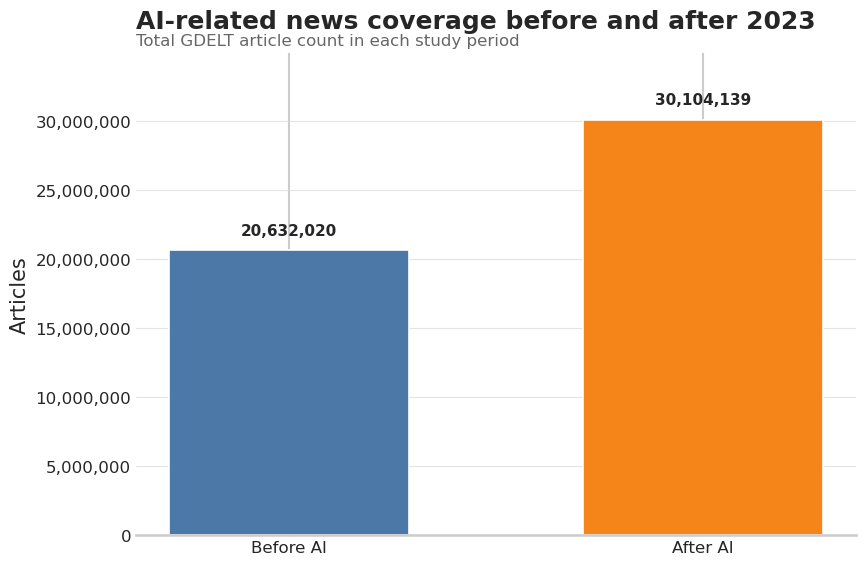

In [99]:
plot_article_count_comparison(comparison_df, RESULT_DIR)

### Mean scores comparison

In [100]:
def plot_mean_scores_comparison(
    comparison_df: pd.DataFrame,
    result_dir: Path,
) -> None:
    """Plot the mean emotional scores for both study periods.

    Args:
        comparison_df: Prepared global comparison data.
        result_dir: Directory in which to save the figure.
    """

    scores_plot_df = comparison_df.set_index("period_label")[SCORE_COLUMNS].T
    scores_plot_df.index = SCORE_LABELS
    fig, ax = plt.subplots(figsize=(10, 6))
    scores_plot_df.plot(
        kind="bar",
        ax=ax,
        color=[PERIOD_COLORS[column] for column in scores_plot_df.columns],
        width=0.72,
        edgecolor="white",
    )
    values = scores_plot_df.to_numpy(dtype=float)
    ax.set_ylim(min(0, values.min() * 1.15), values.max() * 1.18)
    ax.set_title(
        "Emotional tone shifted after the AI cutoff",
        loc="left",
        pad=18,
        fontweight="bold",
    )
    ax.text(
        0,
        1.01,
        "Mean scores across all aggregated location-theme interactions",
        transform=ax.transAxes,
        color="#666666",
        fontsize=12,
        va="bottom",
    )
    ax.set_xlabel("")
    ax.set_ylabel("Mean score")
    ax.tick_params(axis="x", rotation=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))
    ax.legend(title=None, frameon=False, ncols=2, loc="upper right")
    style_global_plot(ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="{:,.3f}", padding=4, fontsize=10)
    fig.tight_layout()
    fig.savefig(
        result_dir / "mean_scores_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

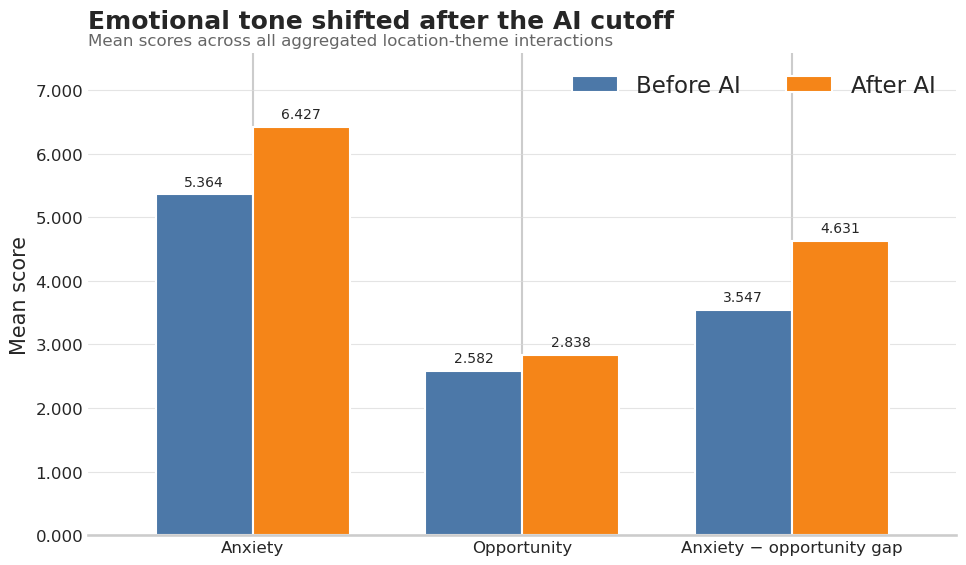

In [101]:
plot_mean_scores_comparison(comparison_df, RESULT_DIR)

### Global Mean Score Maps

In [102]:
MAP_SCORE_COLUMNS = {
    "mean_anxiety_score": "Mean anxiety",
    "mean_opportunity_score": "Mean opportunity",
    "mean_opportunity_minus_anxiety": "Mean opportunity − anxiety",
}
MAP_COLOR_SCALES = {
    "mean_anxiety_score": "OrRd",
    "mean_opportunity_score": "YlGnBu",
    "mean_opportunity_minus_anxiety": "RdBu",
}
# GDELT uses FIPS-style codes for several countries and territories whose
# codes differ from ISO alpha-2. None marks historical or disputed regions
# that cannot be represented as a single current ISO country.
GDELT_COUNTRY_CODE_TO_ISO3 = {
    "AC": "ATG",
    "BK": "BIH",
    "BM": "MMR",
    "BQ": "UMI",
    "BX": "BRN",
    "CG": "COD",
    "CV": "CPV",
    "DQ": "UMI",
    "FM": "FSM",
    "GG": "GEO",
    "GZ": "PSE",
    "HQ": "UMI",
    "IV": "CIV",
    "JN": "SJM",
    "JQ": "UMI",
    "KV": "XKX",
    "LO": "SVK",
    "LQ": "UMI",
    "MC": "MAC",
    "MK": "MKD",
    "MQ": "UMI",
    "NT": None,
    "PA": "PRY",
    "PC": "PCN",
    "PF": None,
    "PG": None,
    "PU": "GNB",
    "RB": "SRB",
    "RE": "REU",
    "RN": "MAF",
    "RS": "RUS",
    "SC": "KNA",
    "SH": "SHN",
    "SV": "SJM",
    "TD": "TTO",
    "TN": "TON",
    "TT": "TLS",
    "TU": "TUR",
    "VC": "VCT",
    "VQ": "VIR",
    "VT": "VAT",
    "WE": "PSE",
    "WQ": "UMI",
    "WS": "WSM",
    "WZ": "SWZ",
    "YI": "SRB",
}


def country_name_to_iso3(
    country_name: object,
    country_code: object,
) -> str | None:
    """Resolve a GDELT country name and code to an ISO-3 country code.

    GDELT country codes are not always ISO alpha-2 codes, so the country name
    is resolved first. The code is used only as a fallback.

    Args:
        country_name: Country name from a GDELT country-level location.
        country_code: GDELT country code.

    Returns:
        ISO-3 code, or None when no country can be resolved.
    """

    if pd.notna(country_code):
        normalized_code = str(country_code).strip().upper()
        if normalized_code in GDELT_COUNTRY_CODE_TO_ISO3:
            return GDELT_COUNTRY_CODE_TO_ISO3[normalized_code]

    if pd.notna(country_name):
        normalized_name = str(country_name).strip()
        if normalized_name:
            try:
                return pycountry.countries.lookup(normalized_name).alpha_3
            except LookupError:
                pass

    if pd.notna(country_code):
        country = pycountry.countries.get(alpha_2=normalized_code)
        if country is not None:
            return country.alpha_3
    return None


def prepare_global_score_map_data(df: pd.DataFrame) -> pd.DataFrame:
    """Aggregate emotional scores by country and period for global maps.

    Args:
        df: Enriched GDELT data containing country locations and mean scores.

    Returns:
        Country-period data with ISO-3 codes and the three requested metrics.

    Raises:
        ValueError: If required columns are missing or no countries resolve.
    """

    required_columns = {
        "location_type",
        "location_name",
        "location_country_code",
        "period",
        "article_count",
        "mean_anxiety_score",
        "mean_opportunity_score",
    }
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    country_rows = df.loc[
        df["location_type"].astype("string").eq("1")
        & df["location_country_code"].notna()
    ].copy()

    country_names = (
        country_rows.groupby(
            ["location_country_code", "location_name"],
            as_index=False,
            observed=True,
            dropna=False,
        )["article_count"]
        .sum()
        .sort_values(
            ["location_country_code", "article_count"],
            ascending=[True, False],
        )
        .drop_duplicates("location_country_code")
        .rename(columns={"article_count": "name_article_count"})
    )
    country_names["country_iso3"] = [
        country_name_to_iso3(name, code)
        for name, code in zip(
            country_names["location_name"],
            country_names["location_country_code"],
        )
    ]
    country_rows = country_rows.merge(
        country_names[
            ["location_country_code", "country_iso3"]
        ],
        on="location_country_code",
        how="left",
    ).dropna(subset=["country_iso3"])
    map_df = (
        country_rows.groupby(
            ["period", "country_iso3"],
            as_index=False,
            observed=True,
        )
        .agg(
            article_count=("article_count", "sum"),
            mean_anxiety_score=("mean_anxiety_score", "mean"),
            mean_opportunity_score=("mean_opportunity_score", "mean"),
        )
    )
    if map_df.empty:
        raise ValueError("No country names could be resolved to ISO-3 codes.")

    map_df["location_name"] = map_df["country_iso3"].map(
        lambda code: (
            pycountry.countries.get(alpha_3=code).name
            if pycountry.countries.get(alpha_3=code) is not None
            else code
        )
    )
    map_df["location_country_code"] = map_df["country_iso3"]
    map_df["mean_opportunity_minus_anxiety"] = (
        map_df["mean_opportunity_score"] - map_df["mean_anxiety_score"]
    )
    map_df["period_label"] = map_df["period"].map(PERIOD_LABELS)
    map_df["_period_order"] = map_df["period"].astype("string").map(
        {period: index for index, period in enumerate(PERIOD_ORDER)}
    )
    return (
        map_df.sort_values(
            ["_period_order", "location_name"],
            kind="stable",
        )
        .drop(columns="_period_order")
        .reset_index(drop=True)
    )

In [103]:
global_score_map_df = prepare_global_score_map_data(df)
display(global_score_map_df)
save_dataframe_formats(
    global_score_map_df,
    "global_mean_score_map_data",
    RESULT_DIR,
)

,period,country_iso3,article_count,mean_anxiety_score,mean_opportunity_score,location_name,location_country_code,mean_opportunity_minus_anxiety,period_label
0,before_ai,AFG,94489,5.874,2.820,Afghanistan,AFG,-3.053,Before AI
1,before_ai,ALB,25393,4.348,2.460,Albania,ALB,-1.888,Before AI
2,before_ai,DZA,14869,4.685,2.360,Algeria,DZA,-2.325,Before AI
3,before_ai,ASM,399,10.606,2.176,American Samoa,ASM,-8.430,Before AI
4,before_ai,AND,2041,2.696,2.371,Andorra,AND,-0.326,Before AI
...,...,...,...,...,...,...,...,...,...
462,after_ai,ESH,679,10.046,2.318,Western Sahara,ESH,-7.729,After AI
463,after_ai,XKX,15911,15.305,3.271,XKX,XKX,-12.034,After AI
464,after_ai,YEM,10576,6.920,2.797,Yemen,YEM,-4.123,After AI
465,after_ai,ZMB,22257,5.544,3.229,Zambia,ZMB,-2.315,After AI


Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/global_mean_score_map_data.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/global_mean_score_map_data.tex


In [104]:
def plot_score_choropleth_maps(
    map_df: pd.DataFrame,
    result_dir: Path,
    file_prefix: str,
    title_scope: str,
) -> dict[str, Path]:
    """Save interactive and before/after static maps for each score.

    Args:
        map_df: Country-period data containing ISO-3 codes and map scores.
        result_dir: Directory in which to save the HTML and PNG maps.
        file_prefix: Prefix used for each output filename.
        title_scope: Geographic scope shown in each chart title.

    Returns:
        Mapping from score column to its saved HTML path.
    """

    result_dir.mkdir(parents=True, exist_ok=True)
    output_paths = {}
    hover_data = {
        "country_iso3": False,
        "location_country_code": True,
        "period_label": False,
        "article_count": ":,",
        "mean_anxiety_score": ":.3f",
        "mean_opportunity_score": ":.3f",
        "mean_opportunity_minus_anxiety": ":.3f",
    }

    for score_column, score_label in MAP_SCORE_COLUMNS.items():
        figure_kwargs = {}
        if score_column == "mean_opportunity_minus_anxiety":
            color_limit = map_df[score_column].abs().max()
            figure_kwargs["range_color"] = (-color_limit, color_limit)
            figure_kwargs["color_continuous_midpoint"] = 0

        fig = px.choropleth(
            map_df,
            locations="country_iso3",
            color=score_column,
            hover_name="location_name",
            hover_data=hover_data,
            animation_frame="period_label",
            category_orders={
                "period_label": [
                    PERIOD_LABELS[period] for period in PERIOD_ORDER
                ]
            },
            color_continuous_scale=MAP_COLOR_SCALES[score_column],
            projection="natural earth",
            title=f"{title_scope}: {score_label}",
            labels={score_column: score_label},
            **figure_kwargs,
        )
        fig.update_geos(
            showcoastlines=True,
            coastlinecolor="#777777",
            showframe=False,
        )
        fig.update_layout(
            coloraxis_colorbar_title=score_label,
            margin={"l": 0, "r": 0, "t": 70, "b": 0},
        )

        output_path = result_dir / f"{file_prefix}_{score_column}.html"
        fig.write_html(output_path, include_plotlyjs="cdn")
        print(f"Saved interactive map: {output_path}")

        comparison_fig = px.choropleth(
            map_df,
            locations="country_iso3",
            color=score_column,
            hover_name="location_name",
            hover_data=hover_data,
            facet_col="period",
            category_orders={"period": PERIOD_ORDER},
            color_continuous_scale=MAP_COLOR_SCALES[score_column],
            projection="natural earth",
            title=f"{title_scope}: {score_label}",
            labels={score_column: score_label},
            **figure_kwargs,
        )
        for annotation, period in zip(
            comparison_fig.layout.annotations,
            PERIOD_ORDER,
        ):
            annotation.text = period
        comparison_fig.update_geos(
            showcoastlines=True,
            coastlinecolor="#777777",
            showframe=False,
        )
        comparison_fig.update_layout(
            coloraxis_colorbar_title=score_label,
            font={"size": 16},
            margin={"l": 0, "r": 0, "t": 90, "b": 0},
        )
        comparison_path = output_path.with_suffix(".png")
        comparison_fig.write_image(
            comparison_path,
            width=1_800,
            height=800,
            scale=2,
        )
        print(f"Saved before/after map figure: {comparison_path}")
        fig.show()
        output_paths[score_column] = output_path

    return output_paths

In [105]:
global_score_map_paths = plot_score_choropleth_maps(
    global_score_map_df,
    RESULT_DIR,
    file_prefix="global_map",
    title_scope="Global AI emotional tone",
)

Saved interactive map: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/global_map_mean_anxiety_score.html


Saved interactive map: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/global_map_mean_opportunity_score.html


Saved interactive map: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/global_map_mean_opportunity_minus_anxiety.html


### Percentage change after AI

In [106]:
def plot_score_percentage_change(
    comparison_df: pd.DataFrame,
    result_dir: Path,
) -> None:
    """Plot percentage changes in emotional scores after the AI cutoff.

    Args:
        comparison_df: Prepared global comparison data.
        result_dir: Directory in which to save the figure.
    """

    before_scores = comparison_df.loc[0, SCORE_COLUMNS].astype(float)
    after_scores = comparison_df.loc[1, SCORE_COLUMNS].astype(float)
    percentage_values = (
        (after_scores - before_scores) / before_scores * 100
    ).to_numpy()
    colors = [
        POSITIVE_COLOR if value >= 0 else NEGATIVE_COLOR
        for value in percentage_values
    ]
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.bar(
        SCORE_LABELS,
        percentage_values,
        color=colors,
        width=0.62,
        edgecolor="white",
        linewidth=1.2,
    )
    limit = max(max(abs(percentage_values)) * 1.25, 1)
    ax.set_ylim(-limit, limit)
    ax.axhline(0, color="#555555", linewidth=1.1)
    ax.set_title(
        "Relative change in emotional scores after 2023",
        loc="left",
        pad=18,
        fontweight="bold",
    )
    ax.text(
        0,
        1.01,
        "Change relative to the before-AI period",
        transform=ax.transAxes,
        color="#666666",
        fontsize=12,
        va="bottom",
    )
    ax.set_xlabel("")
    ax.set_ylabel("Change from before-AI period")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=1))
    style_global_plot(ax)
    add_bar_labels(
        ax,
        bars,
        [f"{value:+,.2f}%" for value in percentage_values],
        percentage_values,
    )
    fig.tight_layout()
    fig.savefig(
        result_dir / "mean_scores_percentage_change.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

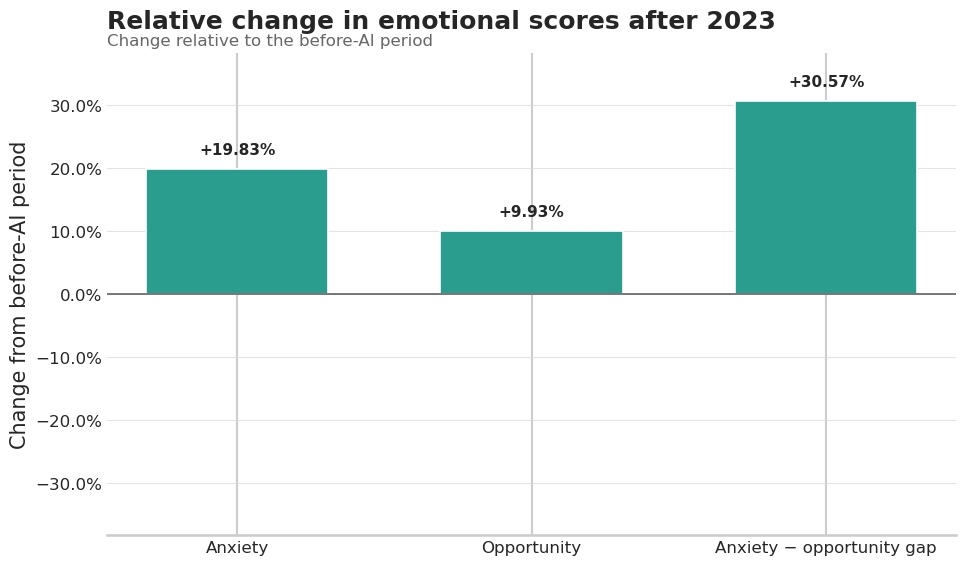

In [107]:
plot_score_percentage_change(comparison_df, RESULT_DIR)

### Article count and locations percentage change

In [108]:
def plot_volume_percentage_change(
    comparison_df: pd.DataFrame,
    result_dir: Path,
) -> None:
    """Plot percentage changes in article and location coverage.

    Args:
        comparison_df: Prepared global comparison data.
        result_dir: Directory in which to save the figure.
    """

    volume_columns = ["article_count", "locations"]
    volume_labels = ["Articles", "Locations"]
    before_volume = comparison_df.loc[0, volume_columns].astype(float)
    after_volume = comparison_df.loc[1, volume_columns].astype(float)
    percentage_values = (
        (after_volume - before_volume) / before_volume * 100
    ).to_numpy()
    colors = [
        POSITIVE_COLOR if value >= 0 else NEGATIVE_COLOR
        for value in percentage_values
    ]
    fig, ax = plt.subplots(figsize=(9, 6))
    bars = ax.bar(
        volume_labels,
        percentage_values,
        color=colors,
        width=0.58,
        edgecolor="white",
        linewidth=1.2,
    )
    y_min = min(0, percentage_values.min())
    y_max = max(0, percentage_values.max())
    padding = max(y_max - y_min, 1) * 0.2
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.axhline(0, color="#555555", linewidth=1.1)
    ax.set_title(
        "Dataset coverage before and after the AI cutoff",
        loc="left",
        pad=18,
        fontweight="bold",
    )
    ax.text(
        0,
        1.01,
        "Change in the volume and geographic breadth of the dataset",
        transform=ax.transAxes,
        color="#666666",
        fontsize=12,
        va="bottom",
    )
    ax.set_ylabel("Change from before-AI period")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=1))
    style_global_plot(ax)
    add_bar_labels(
        ax,
        bars,
        [f"{value:+,.2f}%" for value in percentage_values],
        percentage_values,
    )
    fig.tight_layout()
    fig.savefig(
        result_dir / "data_volume_percentage_change.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

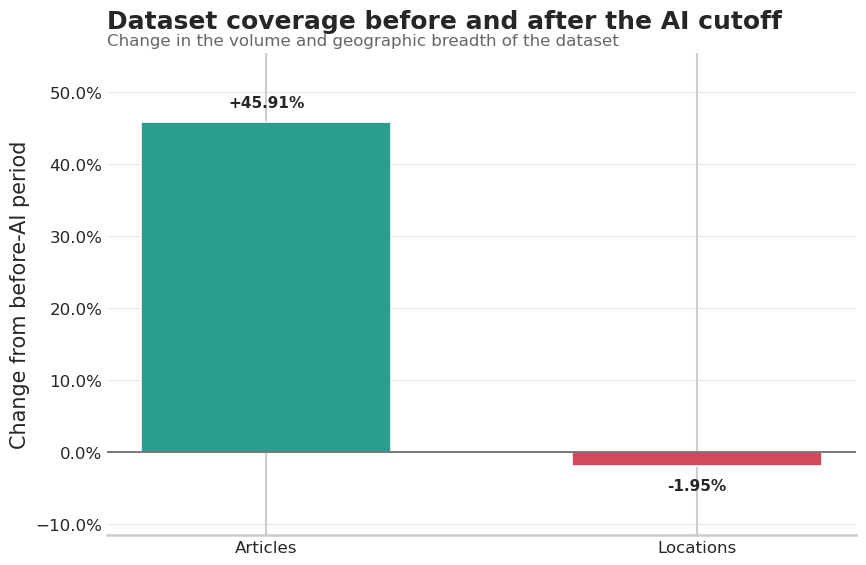

In [109]:
plot_volume_percentage_change(comparison_df, RESULT_DIR)

# Per Location Analysis

## Comparison df

In [110]:
LOCATION_COLUMNS = [
    "location_type",
    "location_name",
    "location_country_code",
    "location_admin1_code",
]


def prepare_location_comparison_data(
    df: pd.DataFrame,
    locations_code_or_names: list[str],
) -> pd.DataFrame:
    """Prepare before- and after-AI comparisons for selected locations.

    Exact location names select that specific location. Country codes select
    country-level GDELT records and combine aliases such as "America" and
    "United States" into one comparison.

    Args:
        df: Enriched GDELT data containing period and analysis columns.
        locations_code_or_names: Location names or country codes to compare.

    Returns:
        Comparison data with the global comparison columns followed by the
        four location-identifying columns.

    Raises:
        ValueError: If the selectors are empty, required columns are missing,
            or a selector does not match the data.
    """

    if not locations_code_or_names:
        raise ValueError("Provide at least one location name or country code.")

    required_columns = {
        "period",
        "article_count",
        *SCORE_COLUMNS,
        *LOCATION_COLUMNS,
    }
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    location_frames = []
    location_names = df["location_name"].astype("string").str.casefold()
    country_codes = df["location_country_code"].astype("string").str.casefold()

    for selector_order, selector in enumerate(locations_code_or_names):
        normalized_selector = selector.strip().casefold()
        if not normalized_selector:
            raise ValueError("Location selectors cannot be empty.")

        name_rows = df.loc[location_names.eq(normalized_selector)]
        if not name_rows.empty:
            selected_groups = name_rows.groupby(
                LOCATION_COLUMNS,
                dropna=False,
                observed=True,
                sort=False,
            )
        else:
            code_rows = df.loc[country_codes.eq(normalized_selector)]
            if code_rows.empty:
                raise ValueError(f"Location '{selector}' was not found.")

            country_rows = code_rows.loc[
                code_rows["location_type"].astype("string").eq("1")
            ]
            if country_rows.empty:
                country_rows = code_rows

            article_counts_by_name = country_rows.groupby(
                "location_name",
                dropna=False,
                observed=True,
            )["article_count"].sum()
            canonical_name = article_counts_by_name.idxmax()
            canonical_rows = country_rows.loc[
                country_rows["location_name"].eq(canonical_name)
            ]
            metadata = tuple(
                canonical_rows[column].iloc[0] for column in LOCATION_COLUMNS
            )
            selected_groups = [(metadata, country_rows)]

        for metadata, location_rows in selected_groups:
            if not isinstance(metadata, tuple):
                metadata = (metadata,)

            location_summary = (
                location_rows.groupby("period", observed=True)
                .agg(
                    article_count=("article_count", "sum"),
                    locations=("location_country_code", "nunique"),
                    mean_anxiety_score=("mean_anxiety_score", "mean"),
                    mean_opportunity_score=("mean_opportunity_score", "mean"),
                    mean_feeling_score=("mean_feeling_score", "mean"),
                )
                .reindex(PERIOD_ORDER)
                .reset_index()
            )
            location_summary["article_count"] = location_summary[
                "article_count"
            ].fillna(0)
            location_summary["locations"] = location_summary["locations"].fillna(0)
            location_summary["period_label"] = location_summary["period"].map(
                PERIOD_LABELS
            )
            for column, value in zip(LOCATION_COLUMNS, metadata):
                location_summary[column] = value
            location_summary["_selector_order"] = selector_order
            location_frames.append(location_summary)

    location_comparison_df = pd.concat(location_frames, ignore_index=True)
    numeric_columns = [
        "article_count",
        "locations",
        *SCORE_COLUMNS,
    ]
    location_comparison_df[numeric_columns] = location_comparison_df[
        numeric_columns
    ].apply(pd.to_numeric)

    location_comparison_df["_period_order"] = (
        location_comparison_df["period"].astype("string").map(
            {period: index for index, period in enumerate(PERIOD_ORDER)}
        )
    )
    location_comparison_df = (
        location_comparison_df.sort_values(
            ["_selector_order", "location_name", "_period_order"],
            kind="stable",
        )
        .drop_duplicates(subset=[*LOCATION_COLUMNS, "period"])
        .reset_index(drop=True)
    )
    return location_comparison_df[COMPARISON_COLUMNS + LOCATION_COLUMNS]

In [111]:
locations_code_or_names = ["Israel", "US"]
location_comparison_df = prepare_location_comparison_data(
    df,
    locations_code_or_names,
)
display(location_comparison_df)
save_dataframe_formats(
    location_comparison_df,
    "per_location_comparison",
    RESULT_DIR,
)

,period,article_count,locations,mean_anxiety_score,mean_opportunity_score,mean_feeling_score,period_label,location_type,location_name,location_country_code,location_admin1_code
0,before_ai,41624,1,5.480,2.744,2.763,Before AI,1,Israel,IS,IS
1,after_ai,76605,1,8.728,3.172,5.938,After AI,1,Israel,IS,IS
2,before_ai,1182178,1,6.868,3.202,3.688,Before AI,1,United States,US,US
3,after_ai,1708991,1,7.163,3.042,4.153,After AI,1,United States,US,US


Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/per_location_comparison.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/per_location_comparison.tex


## Article Count Comparison

In [112]:
def plot_location_article_count_comparison(
    location_comparison_df: pd.DataFrame,
    result_dir: Path,
) -> None:
    """Plot article counts by location before and after the AI cutoff.

    Args:
        location_comparison_df: Prepared per-location comparison data.
        result_dir: Directory in which to save the figure.
    """

    plot_df = location_comparison_df.copy()
    plot_df["location_label"] = (
        plot_df["location_name"].astype(str)
        + " ("
        + plot_df["location_country_code"].astype(str)
        + ")"
    )
    location_order = plot_df["location_label"].drop_duplicates()
    period_labels = [PERIOD_LABELS[period] for period in PERIOD_ORDER]
    article_plot_df = (
        plot_df.pivot(
            index="location_label",
            columns="period_label",
            values="article_count",
        )
        .reindex(index=location_order, columns=period_labels)
    )

    fig, ax = plt.subplots(figsize=(11, 7))
    article_plot_df.plot(
        kind="bar",
        ax=ax,
        color=[PERIOD_COLORS[column] for column in article_plot_df.columns],
        width=0.72,
        edgecolor="white",
        linewidth=1.2,
    )
    values = article_plot_df.to_numpy(dtype=float)
    ax.set_ylim(0, values.max() * 1.18)
    ax.set_title(
        "AI-related news coverage by location",
        loc="left",
        pad=18,
        fontweight="bold",
    )
    ax.text(
        0,
        1.01,
        "Total GDELT article count in each study period",
        transform=ax.transAxes,
        color="#666666",
        fontsize=12,
        va="bottom",
    )
    ax.set_xlabel("")
    ax.set_ylabel("Articles")
    ax.tick_params(axis="x", rotation=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.legend(title=None, frameon=False, ncols=2, loc="upper left")
    style_global_plot(ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="{:,.0f}", padding=4, fontsize=10)
    fig.tight_layout()
    fig.savefig(
        result_dir / "per_location_article_count_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

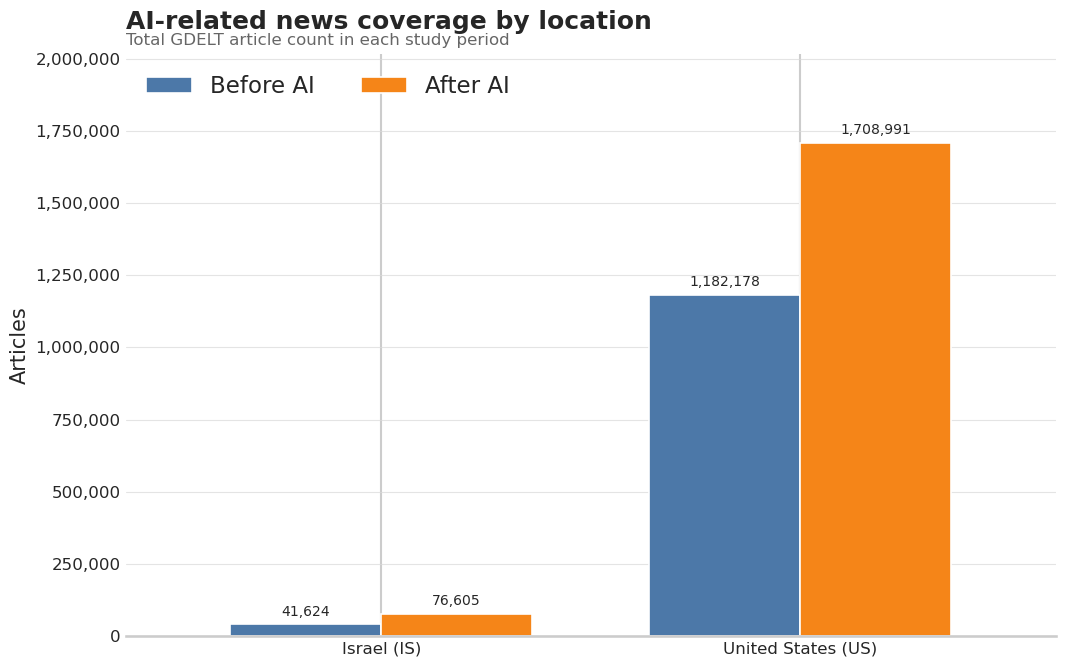

In [113]:
plot_location_article_count_comparison(location_comparison_df, RESULT_DIR)

## Mean Scores Comparison

In [114]:
def plot_location_mean_scores_comparison(
    location_comparison_df: pd.DataFrame,
    result_dir: Path,
) -> None:
    """Plot mean emotional scores for all selected locations and periods.

    Args:
        location_comparison_df: Prepared per-location comparison data.
        result_dir: Directory in which to save the figure.
    """

    plot_df = location_comparison_df.copy()
    plot_df["location_label"] = (
        plot_df["location_name"].astype(str)
        + " ("
        + plot_df["location_country_code"].astype(str)
        + ")"
    )
    location_order = plot_df["location_label"].drop_duplicates()
    period_labels = [PERIOD_LABELS[period] for period in PERIOD_ORDER]
    fig, axes = plt.subplots(1, 3, figsize=(18, 7))

    for ax, metric, title in zip(axes, SCORE_COLUMNS, SCORE_LABELS):
        score_plot_df = (
            plot_df.pivot(
                index="location_label",
                columns="period_label",
                values=metric,
            )
            .reindex(index=location_order, columns=period_labels)
        )
        score_plot_df.plot(
            kind="bar",
            ax=ax,
            color=[PERIOD_COLORS[column] for column in score_plot_df.columns],
            width=0.72,
            edgecolor="white",
        )
        ax.set_title(title, loc="left", fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Mean score")
        ax.tick_params(axis="x", rotation=0)
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))
        for container in ax.containers:
            ax.bar_label(container, fmt="{:,.3f}", padding=3, fontsize=9)
        ax.legend().remove()
        style_global_plot(ax)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        title=None,
        frameon=False,
        ncols=2,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.91),
    )
    fig.suptitle(
        "Emotional tone by location before and after the AI cutoff",
        fontweight="bold",
        y=0.99,
    )
    fig.text(
        0.5,
        0.94,
        "Mean scores across aggregated location-theme interactions",
        ha="center",
        color="#666666",
        fontsize=12,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    fig.savefig(
        result_dir / "per_location_mean_scores_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

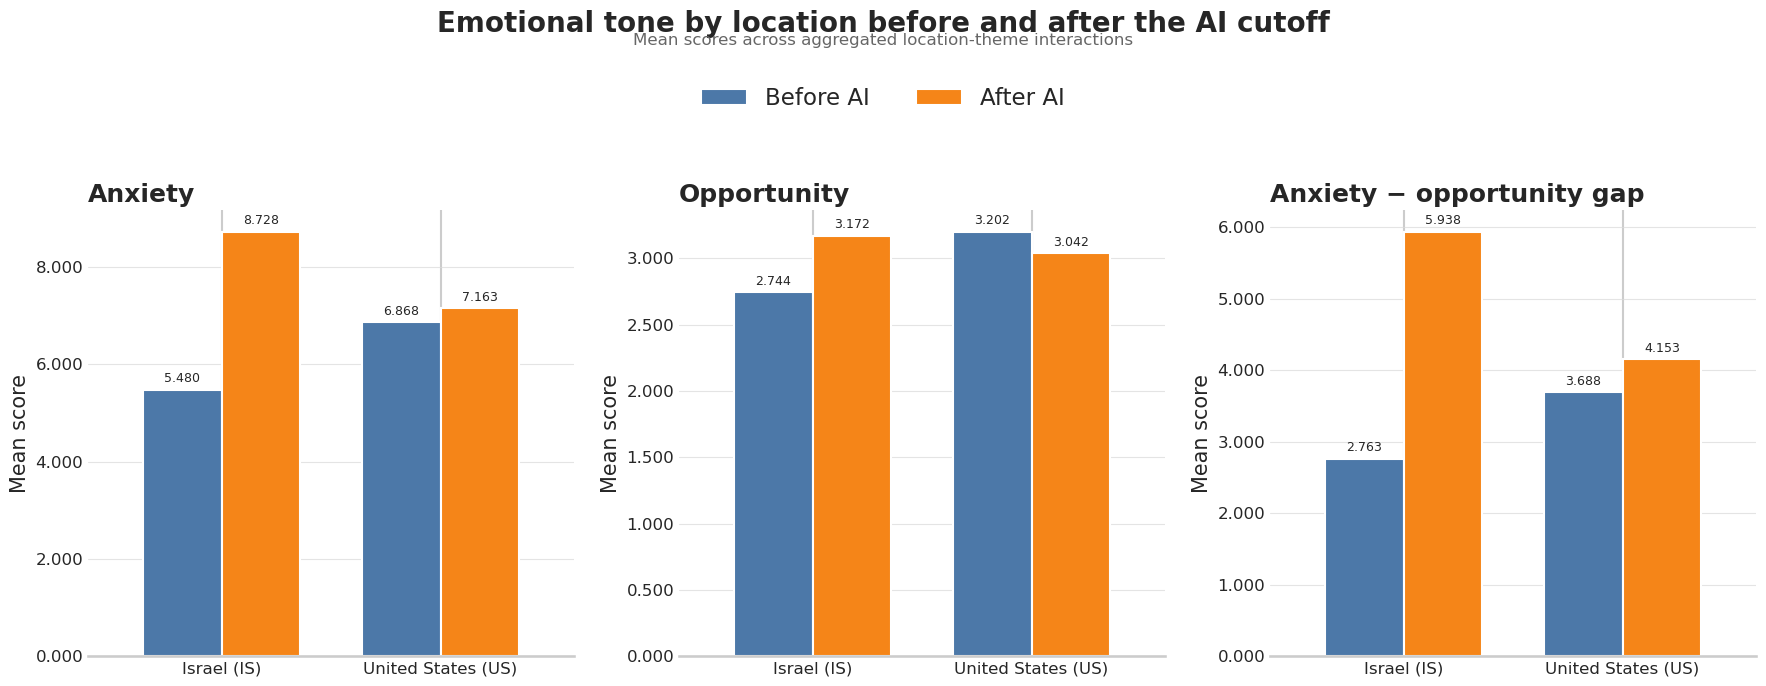

In [115]:
plot_location_mean_scores_comparison(location_comparison_df, RESULT_DIR)

## Selected Location Mean Score Maps

In [116]:
def prepare_selected_location_score_map_data(
    location_comparison_df: pd.DataFrame,
) -> pd.DataFrame:
    """Prepare selected country-level locations for interactive score maps.

    Args:
        location_comparison_df: Prepared before- and after-AI location data.

    Returns:
        Selected location-period data with ISO-3 codes and requested metrics.

    Raises:
        ValueError: If required columns are missing or no countries resolve.
    """

    required_columns = {
        "location_type",
        "location_name",
        "location_country_code",
        "period",
        "period_label",
        "article_count",
        "mean_anxiety_score",
        "mean_opportunity_score",
    }
    missing_columns = required_columns.difference(location_comparison_df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    map_df = location_comparison_df.loc[
        location_comparison_df["location_type"].astype("string").eq("1")
    ].copy()
    if map_df.empty:
        raise ValueError(
            "The selected locations do not include country-level records."
        )

    map_df["country_iso3"] = [
        country_name_to_iso3(name, code)
        for name, code in zip(
            map_df["location_name"],
            map_df["location_country_code"],
        )
    ]
    map_df = map_df.dropna(subset=["country_iso3"]).copy()
    if map_df.empty:
        raise ValueError("No selected locations could be resolved to ISO-3 codes.")

    map_df["mean_opportunity_minus_anxiety"] = (
        map_df["mean_opportunity_score"] - map_df["mean_anxiety_score"]
    )
    return map_df.reset_index(drop=True)

In [117]:
selected_location_score_map_df = prepare_selected_location_score_map_data(
    location_comparison_df
)
display(selected_location_score_map_df)
save_dataframe_formats(
    selected_location_score_map_df,
    "selected_location_mean_score_map_data",
    RESULT_DIR,
)

,period,article_count,locations,mean_anxiety_score,mean_opportunity_score,mean_feeling_score,period_label,location_type,location_name,location_country_code,location_admin1_code,country_iso3,mean_opportunity_minus_anxiety
0,before_ai,41624,1,5.480,2.744,2.763,Before AI,1,Israel,IS,IS,ISR,-2.735
1,after_ai,76605,1,8.728,3.172,5.938,After AI,1,Israel,IS,IS,ISR,-5.556
2,before_ai,1182178,1,6.868,3.202,3.688,Before AI,1,United States,US,US,USA,-3.665
3,after_ai,1708991,1,7.163,3.042,4.153,After AI,1,United States,US,US,USA,-4.121


Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/selected_location_mean_score_map_data.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/selected_location_mean_score_map_data.tex


In [118]:
def plot_selected_location_score_maps(
    selected_location_score_map_df: pd.DataFrame,
    result_dir: Path,
) -> dict[str, Path]:
    """Create the three interactive maps for the selected locations.

    Args:
        selected_location_score_map_df: Selected country-period map data.
        result_dir: Directory in which to save the HTML maps.

    Returns:
        Mapping from score column to its saved HTML path.
    """

    return plot_score_choropleth_maps(
        selected_location_score_map_df,
        result_dir,
        file_prefix="selected_locations_map",
        title_scope="Selected locations AI emotional tone",
    )

In [119]:
selected_location_score_map_paths = plot_selected_location_score_maps(
    selected_location_score_map_df,
    RESULT_DIR,
)

Saved interactive map: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/selected_locations_map_mean_anxiety_score.html


Saved interactive map: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/selected_locations_map_mean_opportunity_score.html


Saved interactive map: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/selected_locations_map_mean_opportunity_minus_anxiety.html


## Negative and Positive Feeling Changes

In [120]:
def compute_location_feeling_changes(
    location_comparison_df: pd.DataFrame,
) -> pd.DataFrame:
    """Compute before/after changes in negative and positive feelings.

    Args:
        location_comparison_df: Prepared per-location comparison data.

    Returns:
        Long-form data with one negative-feeling change and one
        positive-feeling change per location. Changes are calculated as the
        after-AI mean score minus the before-AI mean score.

    Raises:
        ValueError: If required columns are missing or a study period is
            unavailable for a location.
    """

    feeling_columns = {
        "Negative feeling": "mean_anxiety_score",
        "Positive feeling": "mean_opportunity_score",
    }
    required_columns = {
        "location_name",
        "period",
        *feeling_columns.values(),
    }
    missing_columns = required_columns.difference(location_comparison_df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    location_order = (
        location_comparison_df["location_name"].astype(str).drop_duplicates()
    )
    change_frames = []
    for feeling_label, score_column in feeling_columns.items():
        score_table = (
            location_comparison_df.pivot(
                index="location_name",
                columns="period",
                values=score_column,
            )
            .reindex(index=location_order, columns=PERIOD_ORDER)
            .apply(pd.to_numeric)
        )
        if score_table[PERIOD_ORDER].isna().any(axis=None):
            missing_locations = score_table.index[
                score_table[PERIOD_ORDER].isna().any(axis=1)
            ].tolist()
            raise ValueError(
                "Both study periods are required for: "
                + ", ".join(missing_locations)
            )

        change_frames.append(
            pd.DataFrame(
                {
                    "location_name": score_table.index,
                    "feeling": feeling_label,
                    "score_change": (
                        score_table["after_ai"] - score_table["before_ai"]
                    ).to_numpy(dtype=float),
                }
            )
        )

    return pd.concat(change_frames, ignore_index=True)

In [121]:
location_feeling_changes_df = compute_location_feeling_changes(
    location_comparison_df
)
display(location_feeling_changes_df)
save_dataframe_formats(
    location_feeling_changes_df,
    "per_location_feeling_changes",
    RESULT_DIR,
)

,location_name,feeling,score_change
0,Israel,Negative feeling,3.248
1,United States,Negative feeling,0.295
2,Israel,Positive feeling,0.427
3,United States,Positive feeling,-0.161


Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/per_location_feeling_changes.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/per_location_feeling_changes.tex


In [122]:
def plot_location_feeling_changes(
    location_feeling_changes_df: pd.DataFrame,
    result_dir: Path,
) -> None:
    """Plot diverging feeling-score changes using readable location names.

    Args:
        location_feeling_changes_df: Long-form location feeling changes from
            ``compute_location_feeling_changes``.
        result_dir: Directory in which to save the figure.

    Raises:
        ValueError: If required columns are missing or no rows are available.
    """

    required_columns = {"location_name", "feeling", "score_change"}
    missing_columns = required_columns.difference(
        location_feeling_changes_df.columns
    )
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )
    if location_feeling_changes_df.empty:
        raise ValueError("No location feeling changes are available to plot.")

    plot_df = location_feeling_changes_df.copy()
    plot_df["score_change"] = pd.to_numeric(plot_df["score_change"])
    location_order = plot_df["location_name"].astype(str).drop_duplicates()
    feeling_order = ["Negative feeling", "Positive feeling"]
    max_change = plot_df["score_change"].abs().max()
    limit = max(float(max_change) * 1.25, 0.001)
    figure_height = max(6.0, len(location_order) * 0.55 + 2.8)

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, figure_height),
        sharex=True,
        sharey=True,
    )
    for ax, feeling_label in zip(axes, feeling_order):
        feeling_df = (
            plot_df.loc[plot_df["feeling"].eq(feeling_label)]
            .set_index("location_name")
            .reindex(location_order)
        )
        values = feeling_df["score_change"].to_numpy(dtype=float)
        colors = [
            "#5B78A8" if value >= 0 else "#D08B62" for value in values
        ]
        bars = ax.barh(
            location_order,
            values,
            color=colors,
            height=0.68,
            edgecolor="white",
            linewidth=1.2,
        )
        ax.set_xlim(-limit, limit)
        ax.axvline(0, color="#333333", linewidth=1.1)
        ax.set_title(feeling_label, fontweight="bold", pad=12)
        ax.set_xlabel("After AI minus before AI")
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))
        ax.grid(axis="x", color="#D9D9D9", linewidth=0.8, alpha=0.7)
        ax.grid(axis="y", visible=False)
        ax.set_axisbelow(True)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(axis="both", length=0)

        label_padding = limit * 0.025
        for bar, value in zip(bars, values):
            ax.text(
                value + (label_padding if value >= 0 else -label_padding),
                bar.get_y() + bar.get_height() / 2,
                f"{value:+,.3f}",
                ha="left" if value >= 0 else "right",
                va="center",
                fontsize=10,
                fontweight="semibold",
            )

    axes[0].invert_yaxis()
    axes[0].set_ylabel("Location")
    fig.suptitle(
        "Before/After AI Feeling Changes by Location",
        fontweight="bold",
        y=0.99,
    )
    fig.text(
        0.5,
        0.94,
        "Mean negative- and positive-feeling score change after the AI cutoff",
        ha="center",
        color="#666666",
        fontsize=12,
    )
    legend_handles = [
        Line2D([0], [0], color="#5B78A8", linewidth=10, label="Increase"),
        Line2D([0], [0], color="#D08B62", linewidth=10, label="Decrease"),
    ]
    fig.legend(
        handles=legend_handles,
        frameon=False,
        ncols=2,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.91),
    )
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    fig.savefig(
        result_dir / "per_location_feeling_score_changes.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

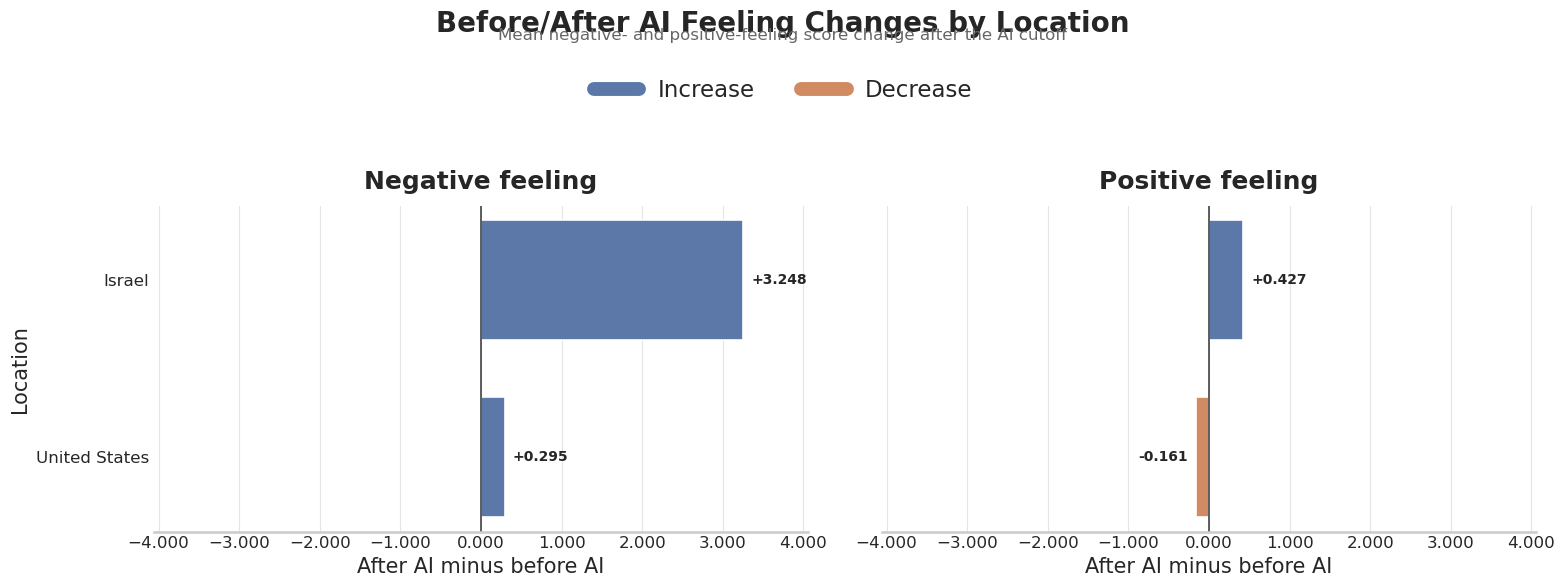

In [123]:
plot_location_feeling_changes(location_feeling_changes_df, RESULT_DIR)

## Article Count Percentage Change

In [124]:
def plot_location_volume_percentage_change(
    location_comparison_df: pd.DataFrame,
    result_dir: Path,
) -> None:
    """Plot article-count percentage changes for selected locations.

    Args:
        location_comparison_df: Prepared per-location comparison data.
        result_dir: Directory in which to save the figure.
    """

    plot_df = location_comparison_df.copy()
    plot_df["location_label"] = (
        plot_df["location_name"].astype(str)
        + " ("
        + plot_df["location_country_code"].astype(str)
        + ")"
    )
    location_order = plot_df["location_label"].drop_duplicates()
    article_plot_df = (
        plot_df.pivot(
            index="location_label",
            columns="period",
            values="article_count",
        )
        .reindex(index=location_order, columns=PERIOD_ORDER)
    )
    percentage_values = (
        (
            article_plot_df["after_ai"] - article_plot_df["before_ai"]
        )
        / article_plot_df["before_ai"]
        * 100
    ).to_numpy(dtype=float)
    colors = [
        POSITIVE_COLOR if value >= 0 else NEGATIVE_COLOR
        for value in percentage_values
    ]

    fig, ax = plt.subplots(figsize=(10, 7))
    bars = ax.bar(
        location_order,
        percentage_values,
        color=colors,
        width=0.58,
        edgecolor="white",
        linewidth=1.2,
    )
    y_min = min(0, np.nanmin(percentage_values))
    y_max = max(0, np.nanmax(percentage_values))
    padding = max(y_max - y_min, 1) * 0.2
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.axhline(0, color="#555555", linewidth=1.1)
    ax.set_title(
        "Article-count change by location",
        loc="left",
        pad=18,
        fontweight="bold",
    )
    ax.text(
        0,
        1.01,
        "Change after the AI cutoff relative to the before-AI period",
        transform=ax.transAxes,
        color="#666666",
        fontsize=12,
        va="bottom",
    )
    ax.set_xlabel("")
    ax.set_ylabel("Change from before-AI period")
    ax.tick_params(axis="x", rotation=0)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=1))
    style_global_plot(ax)
    add_bar_labels(
        ax,
        bars,
        [f"{value:+,.2f}%" for value in percentage_values],
        percentage_values,
    )
    fig.tight_layout()
    fig.savefig(
        result_dir / "per_location_article_count_percentage_change.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

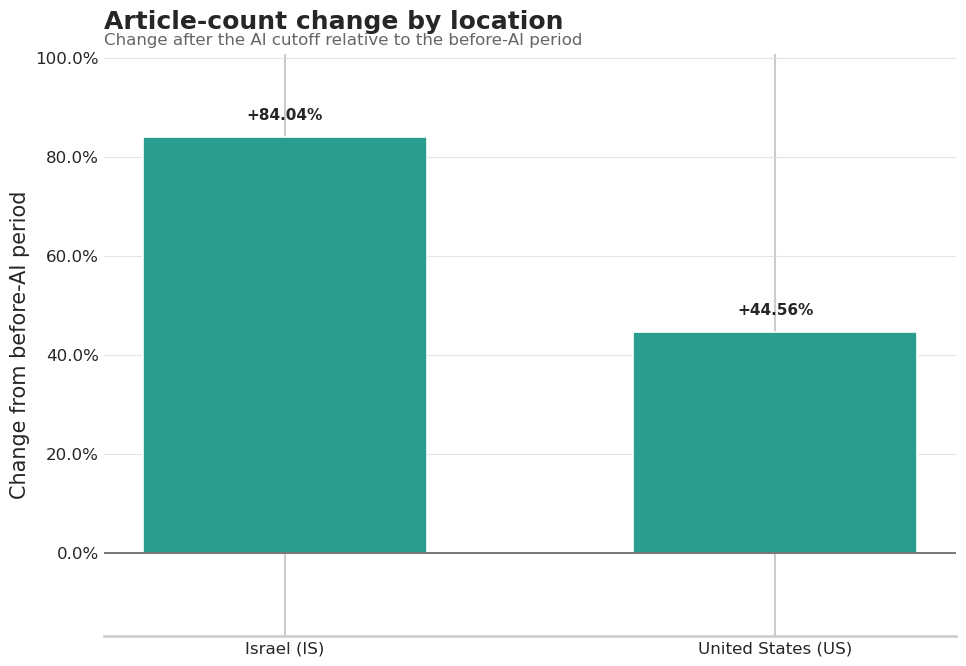

In [125]:
plot_location_volume_percentage_change(location_comparison_df, RESULT_DIR)

# Bipartite Network Construction

The bipartite network connects locations to emotion measures. Location nodes
are ranked by their total interactions, while edge weights represent the mean
emotion score for a location during a study period.

## Edge Table

In [126]:
EMOTION_LABELS = {
    "liwc_anger_avg": "LIWC anger",
    "liwc_anxiety_avg": "LIWC anxiety",
    "lm_uncertainty_avg": "LM uncertainty",
    "wordnet_anger_avg": "WordNet anger",
    "wordnet_anxiety_avg": "WordNet anxiety",
    "wordnet_fear_avg": "WordNet fear",
    "wordnet_hope_avg": "WordNet hope",
    "wordnet_optimism_avg": "WordNet optimism",
    "wordnet_feeling_avg": "WordNet overall feeling",
}

EMOTION_GROUPS = {
    "liwc_anger_avg": "negative",
    "liwc_anxiety_avg": "negative",
    "lm_uncertainty_avg": "negative",
    "wordnet_anger_avg": "negative",
    "wordnet_anxiety_avg": "negative",
    "wordnet_fear_avg": "negative",
    "wordnet_hope_avg": "positive",
    "wordnet_optimism_avg": "positive",
    "wordnet_feeling_avg": "overall",
}

EMOTION_COLORS = {
    "positive": "#54A24B",
    "negative": "#E45756",
    "overall": "#9D9D9D",
}

DIFFERENCE_EDGE_COLORS = {
    "increase": "#7A5195",
    "decrease": "#F28E2B",
}


def build_bipartite_edges(
    df: pd.DataFrame,
    min_interactions: int = MIN_INTERACTIONS_PER_COMMUNITY,
    top_locations: int = TOP_COMMUNITIES_TO_PLOT,
) -> pd.DataFrame:
    """Build period-specific weighted location-emotion edges.

    Args:
        df: Enriched aggregate data containing period, location, interaction,
            and feeling columns.
        min_interactions: Minimum total interactions required for a location
            to be included in a period.
        top_locations: Maximum number of locations retained per period.

    Returns:
        Long DataFrame containing location-emotion edges and their weights.

    Raises:
        ValueError: If required columns are missing or no valid edges remain.
    """

    required_columns = {
        "period",
        "location_type",
        "location_name",
        "location_country_code",
        "article_count",
        "interaction_count",
        *FEELING_COLUMNS,
    }
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    graph_columns = [
        "period",
        "location_type",
        "location_name",
        "location_country_code",
        "article_count",
        "interaction_count",
        *FEELING_COLUMNS,
    ]
    country_codes = df["location_country_code"]
    valid_location_mask = country_codes.notna() & ~country_codes.isin(
        ["", "unknown", "Unknown", "UNKNOWN"]
    )
    valid_df = df.loc[valid_location_mask, graph_columns]
    del country_codes, valid_location_mask

    location_summary = (
        valid_df.groupby(
            ["period", "location_country_code"],
            as_index=False,
            observed=True,
        )
        .agg(
            interaction_count=("interaction_count", "sum"),
            **{column: (column, "mean") for column in FEELING_COLUMNS},
        )
        .loc[lambda table: table["interaction_count"] >= min_interactions]
        .sort_values(
            ["period", "interaction_count"],
            ascending=[True, False],
        )
        .groupby("period", as_index=False, observed=True)
        .head(top_locations)
    )

    country_rows = valid_df.loc[
        valid_df["location_type"].astype("string").eq("1")
    ]
    canonical_locations = (
        country_rows.groupby(
            ["location_country_code", "location_name"],
            as_index=False,
            observed=True,
        )
        .agg(article_count=("article_count", "sum"))
        .sort_values(
            ["location_country_code", "article_count"],
            ascending=[True, False],
        )
        .drop_duplicates("location_country_code")
        [["location_country_code", "location_name"]]
    )

    edges = (
        location_summary.merge(
            canonical_locations,
            on="location_country_code",
            how="left",
        )
        .assign(
            location_name=lambda table: table["location_name"].fillna(
                table["location_country_code"]
            ),
            location_label=lambda table: (
                table["location_name"].astype(str)
                + " ("
                + table["location_country_code"].astype(str)
                + ")"
            ),
        )
        .melt(
            id_vars=[
                "period",
                "location_country_code",
                "location_name",
                "location_label",
                "interaction_count",
            ],
            value_vars=FEELING_COLUMNS,
            var_name="emotion",
            value_name="weight",
        )
        .dropna(subset=["weight"])
        .loc[lambda table: table["weight"] > 0]
    )
    edges["emotion_label"] = edges["emotion"].map(EMOTION_LABELS)
    edges = edges.sort_values(
        ["period", "interaction_count", "weight"],
        ascending=[True, False, False],
    ).reset_index(drop=True)

    if edges.empty:
        raise ValueError("No location-emotion edges satisfy the thresholds.")
    return edges[
        [
            "period",
            "location_country_code",
            "location_name",
            "location_label",
            "interaction_count",
            "emotion",
            "emotion_label",
            "weight",
        ]
    ]

In [127]:
bipartite_edges = build_bipartite_edges(df)
# del df
# gc.collect()
display(bipartite_edges.head(20))
save_dataframe_formats(
    bipartite_edges,
    "location_emotion_bipartite_edges",
    RESULT_DIR,
)

,period,location_country_code,location_name,location_label,interaction_count,emotion,emotion_label,weight
0,after_ai,RS,Russia,Russia (RS),20751534,wordnet_feeling_avg,WordNet overall feeling,148.987
1,after_ai,RS,Russia,Russia (RS),20751534,liwc_anger_avg,LIWC anger,97.881
2,after_ai,RS,Russia,Russia (RS),20751534,wordnet_anger_avg,WordNet anger,66.573
3,after_ai,RS,Russia,Russia (RS),20751534,lm_uncertainty_avg,LM uncertainty,61.619
4,after_ai,RS,Russia,Russia (RS),20751534,liwc_anxiety_avg,LIWC anxiety,18.084
5,after_ai,RS,Russia,Russia (RS),20751534,wordnet_hope_avg,WordNet hope,5.339
6,after_ai,RS,Russia,Russia (RS),20751534,wordnet_anxiety_avg,WordNet anxiety,4.937
7,after_ai,RS,Russia,Russia (RS),20751534,wordnet_optimism_avg,WordNet optimism,2.905
8,after_ai,RS,Russia,Russia (RS),20751534,wordnet_fear_avg,WordNet fear,2.808
9,after_ai,US,United States,United States (US),16045286,wordnet_feeling_avg,WordNet overall feeling,18.699


Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/location_emotion_bipartite_edges.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/location_emotion_bipartite_edges.tex


## Network Graphs

In [128]:
def build_bipartite_graph(
    edge_table: pd.DataFrame,
    period: str,
    max_edges: int = MAX_GRAPH_EDGES,
) -> nx.Graph:
    """Build a weighted location-emotion graph for one period.

    Args:
        edge_table: Location-emotion edge table.
        period: Study period to include.
        max_edges: Maximum number of strongest edges retained.

    Returns:
        NetworkX bipartite graph with location and emotion node attributes.

    Raises:
        ValueError: If the period has no edges.
    """

    period_edges = (
        edge_table.loc[edge_table["period"].astype(str).eq(period)]
        .sort_values("weight", ascending=False)
        .head(max_edges)
    )
    if period_edges.empty:
        raise ValueError(f"No bipartite edges are available for '{period}'.")

    graph = nx.Graph(period=period)
    for row in period_edges.itertuples(index=False):
        location_node = f"location::{row.location_country_code}"
        emotion_node = f"emotion::{row.emotion}"
        graph.add_node(
            location_node,
            node_type="location",
            bipartite=0,
            label=row.location_label,
            interaction_count=int(row.interaction_count),
        )
        graph.add_node(
            emotion_node,
            node_type="emotion",
            bipartite=1,
            label=row.emotion_label,
            emotion_group=EMOTION_GROUPS[row.emotion],
        )
        graph.add_edge(
            location_node,
            emotion_node,
            weight=float(row.weight),
        )
    return graph


def summarize_bipartite_graphs(
    graphs: dict[str, nx.Graph],
) -> pd.DataFrame:
    """Summarize the size and density of bipartite graphs.

    Args:
        graphs: Graphs keyed by study period.

    Returns:
        DataFrame with node, edge, and bipartite-density statistics.
    """

    records = []
    for period, graph in graphs.items():
        location_nodes = [
            node
            for node, attributes in graph.nodes(data=True)
            if attributes["node_type"] == "location"
        ]
        emotion_nodes = [
            node
            for node, attributes in graph.nodes(data=True)
            if attributes["node_type"] == "emotion"
        ]
        records.append(
            {
                "period": period,
                "locations": len(location_nodes),
                "emotions": len(emotion_nodes),
                "nodes": graph.number_of_nodes(),
                "edges": graph.number_of_edges(),
                "bipartite_density": nx.bipartite.density(
                    graph,
                    location_nodes,
                ),
            }
        )
    return pd.DataFrame(records)

In [129]:
bipartite_graphs = {
    period: build_bipartite_graph(bipartite_edges, period)
    for period in PERIOD_ORDER
}
bipartite_graph_summary = summarize_bipartite_graphs(bipartite_graphs)
display(bipartite_graph_summary)
save_dataframe_formats(
    bipartite_graph_summary,
    "location_emotion_bipartite_graph_summary",
    RESULT_DIR,
)

,period,locations,emotions,nodes,edges,bipartite_density
0,before_ai,20,8,28,120,0.750
1,after_ai,20,9,29,120,0.667


Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/location_emotion_bipartite_graph_summary.csv
Saved DataFrame: /home/amitner/Data-Mining-Assignments/Project/results/start_2022-12-01_cutoff_2023-01-01_end_2023-02-01/location_emotion_bipartite_graph_summary.tex


## Network Visualization

In [130]:
def plot_bipartite_networks(
    graphs: dict[str, nx.Graph],
    result_dir: Path,
) -> None:
    """Plot period-specific location-emotion networks side by side.

    Args:
        graphs: Bipartite graphs keyed by study period.
        result_dir: Directory in which to save the figure.
    """

    periods = [period for period in PERIOD_ORDER if period in graphs]
    fig, axes = plt.subplots(
        1,
        len(periods),
        figsize=(13 * len(periods), 12),
        squeeze=False,
    )

    for ax, period in zip(axes.flat, periods):
        graph = graphs[period]
        location_nodes = sorted(
            (
                node
                for node, attributes in graph.nodes(data=True)
                if attributes["node_type"] == "location"
            ),
            key=lambda node: graph.nodes[node]["interaction_count"],
            reverse=True,
        )
        emotion_nodes = sorted(
            (
                node
                for node, attributes in graph.nodes(data=True)
                if attributes["node_type"] == "emotion"
            ),
            key=lambda node: graph.nodes[node]["label"],
        )
        positions = {
            node: (0, y_position)
            for node, y_position in zip(
                location_nodes,
                np.linspace(1, -1, len(location_nodes)),
            )
        }
        positions.update(
            {
                node: (1, y_position)
                for node, y_position in zip(
                    emotion_nodes,
                    np.linspace(1, -1, len(emotion_nodes)),
                )
            }
        )

        edge_weights = np.array(
            [
                attributes["weight"]
                for _, _, attributes in graph.edges(data=True)
            ],
            dtype=float,
        )
        edge_widths = 1 + 6 * edge_weights / edge_weights.max()
        nx.draw_networkx_edges(
            graph,
            positions,
            ax=ax,
            width=edge_widths,
            edge_color="#888888",
            alpha=0.38,
        )
        nx.draw_networkx_nodes(
            graph,
            positions,
            nodelist=location_nodes,
            node_color="#4C78A8",
            node_size=950,
            edgecolors="white",
            linewidths=1,
            ax=ax,
        )
        nx.draw_networkx_nodes(
            graph,
            positions,
            nodelist=emotion_nodes,
            node_color=[
                EMOTION_COLORS[
                    graph.nodes[node].get(
                        "emotion_group",
                        EMOTION_GROUPS[node.split("::", maxsplit=1)[1]],
                    )
                ]
                for node in emotion_nodes
            ],
            node_size=950,
            edgecolors="white",
            linewidths=1,
            ax=ax,
        )

        for node in location_nodes:
            x_position, y_position = positions[node]
            ax.text(
                x_position - 0.055,
                y_position,
                graph.nodes[node]["label"],
                ha="right",
                va="center",
                fontsize=14,
            )
        for node in emotion_nodes:
            x_position, y_position = positions[node]
            ax.text(
                x_position + 0.055,
                y_position,
                graph.nodes[node]["label"],
                ha="left",
                va="center",
                fontsize=14,
            )

        ax.set_title(
            PERIOD_LABELS[period],
            fontsize=22,
            fontweight="bold",
            pad=14,
        )
        ax.set_xlim(-0.5, 1.5)
        ax.set_ylim(-1.05, 1.05)
        ax.axis("off")

    legend_items = [
        ("Locations", "#4C78A8"),
        ("Positive feelings", EMOTION_COLORS["positive"]),
        ("Negative feelings", EMOTION_COLORS["negative"]),
        ("Overall feeling", EMOTION_COLORS["overall"]),
    ]
    legend_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor=color,
            markeredgecolor="white",
            markersize=15,
            label=label,
        )
        for label, color in legend_items
    ]
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncols=4,
        bbox_to_anchor=(0.5, 0.015),
        frameon=False,
        fontsize=16,
        columnspacing=2.4,
        handletextpad=0.6,
    )
    fig.suptitle(
        "Location–emotion bipartite networks",
        fontsize=28,
        fontweight="bold",
        y=0.98,
    )
    fig.text(
        0.5,
        0.925,
        (
            "Edge width represents the mean emotion score"
        ),
        ha="center",
        color="#666666",
        fontsize=16,
        fontweight="semibold",
    )
    fig.tight_layout(rect=(0.01, 0.09, 0.99, 0.9), w_pad=3)
    fig.savefig(
        result_dir / "location_emotion_bipartite_networks.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [ ]:
plot_bipartite_networks(bipartite_graphs, RESULT_DIR)

# Location Similarity Network

The location-only network projects the period-specific bipartite network.
For every pair of locations, the similarity weight is the sum of the minimum
location weights across emotions shared by both locations:

`similarity(A, B) = Σ min(weight(A, feeling), weight(B, feeling))`

## Similarity Edge Table

In [ ]:
def compute_location_similarity_edges(
    edge_table: pd.DataFrame,
) -> pd.DataFrame:
    """Compute period-specific similarities for every location pair.

    For each location pair, the function aligns shared emotions, takes the
    minimum of the two location weights for each emotion, and sums those
    minimum values.

    Args:
        edge_table: Period-specific location-emotion edge table.

    Returns:
        DataFrame containing every unique location pair and its similarity
        weight for each period.

    Raises:
        ValueError: If required columns are missing, duplicate
            location-emotion rows exist, or no location pairs are available.
    """

    required_columns = {
        "period",
        "location_country_code",
        "location_name",
        "location_label",
        "interaction_count",
        "emotion",
        "weight",
    }
    missing_columns = required_columns.difference(edge_table.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    duplicate_keys = ["period", "location_country_code", "emotion"]
    if edge_table.duplicated(duplicate_keys).any():
        raise ValueError(
            "The edge table must contain one row per period, location, "
            "and emotion."
        )

    available_periods = (
        edge_table["period"].astype(str).drop_duplicates().tolist()
    )
    ordered_periods = [
        period for period in PERIOD_ORDER if period in available_periods
    ]
    ordered_periods.extend(
        sorted(set(available_periods).difference(ordered_periods))
    )

    records = []
    for period in ordered_periods:
        period_edges = edge_table.loc[
            edge_table["period"].astype(str).eq(period)
        ].copy()
        location_metadata = (
            period_edges[
                [
                    "location_country_code",
                    "location_name",
                    "location_label",
                    "interaction_count",
                ]
            ]
            .drop_duplicates("location_country_code")
            .set_index("location_country_code")
        )
        location_weights = {
            location_code: location_rows.set_index("emotion")["weight"].astype(
                float
            )
            for location_code, location_rows in period_edges.groupby(
                "location_country_code",
                observed=True,
                sort=True,
            )
        }

        location_codes = sorted(
            location_weights,
            key=str,
        )
        for location_a, location_b in combinations(location_codes, 2):
            weights_a = location_weights[location_a]
            weights_b = location_weights[location_b]
            shared_feelings = weights_a.index.intersection(weights_b.index)
            if shared_feelings.empty:
                similarity_weight = 0.0
            else:
                similarity_weight = float(
                    np.minimum(
                        weights_a.loc[shared_feelings].to_numpy(),
                        weights_b.loc[shared_feelings].to_numpy(),
                    ).sum()
                )

            metadata_a = location_metadata.loc[location_a]
            metadata_b = location_metadata.loc[location_b]
            records.append(
                {
                    "period": period,
                    "location_a_country_code": location_a,
                    "location_a_name": metadata_a["location_name"],
                    "location_a_label": metadata_a["location_label"],
                    "location_a_interaction_count": int(
                        metadata_a["interaction_count"]
                    ),
                    "location_b_country_code": location_b,
                    "location_b_name": metadata_b["location_name"],
                    "location_b_label": metadata_b["location_label"],
                    "location_b_interaction_count": int(
                        metadata_b["interaction_count"]
                    ),
                    "shared_feeling_count": int(len(shared_feelings)),
                    "similarity_weight": similarity_weight,
                }
            )

    if not records:
        raise ValueError(
            "At least two locations in one period are required to compute "
            "similarity edges."
        )

    similarity_table = pd.DataFrame(records)
    period_rank = {
        period: rank for rank, period in enumerate(ordered_periods)
    }
    similarity_table["_period_rank"] = similarity_table["period"].map(
        period_rank
    )
    return (
        similarity_table.sort_values(
            [
                "_period_rank",
                "similarity_weight",
                "location_a_country_code",
                "location_b_country_code",
            ],
            ascending=[True, False, True, True],
        )
        .drop(columns="_period_rank")
        .reset_index(drop=True)
    )

In [ ]:
location_similarity_edges = compute_location_similarity_edges(
    bipartite_edges
)
display(location_similarity_edges.head(20))
save_dataframe_formats(
    location_similarity_edges,
    "location_similarity_edges",
    RESULT_DIR,
)

## Similarity Graphs

In [ ]:
def build_location_similarity_graph(
    similarity_table: pd.DataFrame,
    period: str,
) -> nx.Graph:
    """Build a complete weighted location-similarity graph for one period.

    Args:
        similarity_table: Location-pair similarity table.
        period: Study period to include.

    Returns:
        NetworkX graph containing all locations and computed pair weights.

    Raises:
        ValueError: If required columns are missing, the period has no rows,
            or duplicate location pairs exist.
    """

    required_columns = {
        "period",
        "location_a_country_code",
        "location_a_label",
        "location_a_interaction_count",
        "location_b_country_code",
        "location_b_label",
        "location_b_interaction_count",
        "shared_feeling_count",
        "similarity_weight",
    }
    missing_columns = required_columns.difference(similarity_table.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    period_edges = similarity_table.loc[
        similarity_table["period"].astype(str).eq(period)
    ].copy()
    if period_edges.empty:
        raise ValueError(
            f"No location similarity edges are available for '{period}'."
        )

    pair_columns = [
        "location_a_country_code",
        "location_b_country_code",
    ]
    if period_edges.duplicated(pair_columns).any():
        raise ValueError(
            "The similarity table must contain one row per location pair."
        )

    graph = nx.Graph(
        period=period,
        candidate_edge_count=int(len(period_edges)),
    )
    for row in period_edges.itertuples(index=False):
        location_a = f"location::{row.location_a_country_code}"
        location_b = f"location::{row.location_b_country_code}"
        graph.add_node(
            location_a,
            label=row.location_a_label,
            country_code=row.location_a_country_code,
            interaction_count=int(row.location_a_interaction_count),
        )
        graph.add_node(
            location_b,
            label=row.location_b_label,
            country_code=row.location_b_country_code,
            interaction_count=int(row.location_b_interaction_count),
        )
        graph.add_edge(
            location_a,
            location_b,
            weight=float(row.similarity_weight),
            similarity_weight=float(row.similarity_weight),
            shared_feeling_count=int(row.shared_feeling_count),
        )

    for node, weighted_degree in graph.degree(weight="weight"):
        graph.nodes[node]["weighted_degree"] = float(weighted_degree)
    graph.graph["location_count"] = int(graph.number_of_nodes())
    graph.graph["positive_edge_count"] = int(
        sum(
            attributes["similarity_weight"] > 0
            for _, _, attributes in graph.edges(data=True)
        )
    )
    return graph

In [ ]:
location_similarity_graphs = {
    period: build_location_similarity_graph(
        location_similarity_edges,
        period,
    )
    for period in PERIOD_ORDER
}
location_similarity_graph_summary = pd.DataFrame(
    [
        {
            "period": period,
            "locations": graph.graph["location_count"],
            "edges": graph.number_of_edges(),
            "positive_edges": graph.graph["positive_edge_count"],
            "density": nx.density(graph),
        }
        for period, graph in location_similarity_graphs.items()
    ]
)
display(location_similarity_graph_summary)
save_dataframe_formats(
    location_similarity_graph_summary,
    "location_similarity_graph_summary",
    RESULT_DIR,
)

## Similarity Network Visualization

In [ ]:
def plot_location_similarity_networks(
    graphs: dict[str, nx.Graph],
    result_dir: Path,
    max_edges: int = 60,
    seed: int = 42,
) -> None:
    """Plot period-specific location similarity networks side by side.

    A shared weighted spring layout is calculated from the union of all period
    graphs so locations use comparable positions across panels. All edges
    influence the layout, while only the strongest ``max_edges`` are drawn.

    Args:
        graphs: Location similarity graphs keyed by study period.
        result_dir: Directory in which to save the figure.
        max_edges: Maximum number of strongest edges drawn per period.
        seed: Random seed used by the deterministic spring layout.

    Raises:
        ValueError: If ``max_edges`` is not positive or no valid graphs exist.
    """

    if max_edges <= 0:
        raise ValueError("max_edges must be a positive integer.")
    periods = [period for period in PERIOD_ORDER if period in graphs]
    if not periods:
        raise ValueError("No study-period similarity graphs are available.")

    layout_graph = nx.Graph()
    layout_edge_weights: dict[tuple[str, str], list[float]] = {}
    for period in periods:
        graph = graphs[period]
        layout_graph.add_nodes_from(graph.nodes(data=True))
        for source, target, attributes in graph.edges(data=True):
            edge_key = tuple(sorted((source, target)))
            layout_edge_weights.setdefault(edge_key, []).append(
                float(attributes["similarity_weight"])
            )
    for (source, target), weights in layout_edge_weights.items():
        layout_graph.add_edge(
            source,
            target,
            weight=float(np.mean(weights)),
        )

    shared_positions = nx.spring_layout(
        layout_graph,
        seed=seed,
        weight="weight",
        k=0.55,
        iterations=300,
    )
    x_values = np.array(
        [position[0] for position in shared_positions.values()]
    )
    y_values = np.array(
        [position[1] for position in shared_positions.values()]
    )
    x_padding = max(x_values.max() - x_values.min(), 1) * 0.18
    y_padding = max(y_values.max() - y_values.min(), 1) * 0.18

    fig, axes = plt.subplots(
        1,
        len(periods),
        figsize=(13 * len(periods), 12),
        squeeze=False,
    )
    displayed_counts = {}
    candidate_counts = {}

    for ax, period in zip(axes.flat, periods):
        graph = graphs[period]
        period_positions = {
            node: shared_positions[node] for node in graph.nodes
        }
        positive_edges = [
            (source, target, attributes)
            for source, target, attributes in graph.edges(data=True)
            if attributes["similarity_weight"] > 0
        ]
        displayed_edges = sorted(
            positive_edges,
            key=lambda edge: edge[2]["similarity_weight"],
            reverse=True,
        )[:max_edges]
        displayed_counts[period] = len(displayed_edges)
        candidate_counts[period] = graph.number_of_edges()

        similarity_weights = np.array(
            [
                attributes["similarity_weight"]
                for _, _, attributes in displayed_edges
            ],
            dtype=float,
        )
        if similarity_weights.size:
            edge_widths = (
                0.7
                + 5
                * np.sqrt(
                    similarity_weights / similarity_weights.max()
                )
            )
            nx.draw_networkx_edges(
                graph,
                period_positions,
                ax=ax,
                edgelist=[
                    (source, target)
                    for source, target, _ in displayed_edges
                ],
                width=edge_widths,
                edge_color="#777777",
                alpha=0.32,
            )

        nx.draw_networkx_nodes(
            graph,
            period_positions,
            ax=ax,
            node_color="#4C78A8",
            node_size=950,
            edgecolors="white",
            linewidths=1,
        )
        for node, (x_position, y_position) in period_positions.items():
            position_norm = max(
                np.hypot(x_position, y_position),
                0.1,
            )
            x_offset = 15 * x_position / position_norm
            y_offset = 15 * y_position / position_norm
            horizontal_alignment = (
                "left"
                if x_offset > 3
                else "right"
                if x_offset < -3
                else "center"
            )
            vertical_alignment = (
                "bottom" if y_offset >= 0 else "top"
            )
            ax.annotate(
                graph.nodes[node]["label"],
                xy=(x_position, y_position),
                xytext=(x_offset, y_offset),
                textcoords="offset points",
                ha=horizontal_alignment,
                va=vertical_alignment,
                fontsize=13,
                bbox={
                    "boxstyle": "round,pad=0.15",
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.72,
                },
            )

        ax.set_title(
            PERIOD_LABELS.get(period, period.replace("_", " ").title()),
            fontsize=22,
            fontweight="bold",
            pad=16,
        )
        ax.set_xlim(x_values.min() - x_padding, x_values.max() + x_padding)
        ax.set_ylim(y_values.min() - y_padding, y_values.max() + y_padding)
        ax.axis("off")

    legend_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor="#4C78A8",
            markeredgecolor="white",
            markersize=15,
            label="Locations",
        ),
        Line2D(
            [0],
            [0],
            color="#777777",
            linewidth=4,
            label="Similarity weight",
        ),
    ]
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncols=2,
        bbox_to_anchor=(0.5, 0.015),
        frameon=False,
        fontsize=16,
        columnspacing=2.5,
        handletextpad=0.7,
    )

    count_descriptions = [
        (
            f"{PERIOD_LABELS.get(period, period)}: "
            f"{displayed_counts[period]:,} of "
            f"{candidate_counts[period]:,}"
        )
        for period in periods
    ]
    fig.suptitle(
        "Location similarity networks",
        fontsize=28,
        fontweight="bold",
        y=0.98,
    )
    fig.text(
        0.5,
        0.925,
        (
            "Edge weight = Σ min(shared feeling weights)  •  "
            "All locations shown  •  "
            f"Strongest edges shown ({'; '.join(count_descriptions)})"
        ),
        ha="center",
        color="#666666",
        fontsize=16,
        fontweight="semibold",
    )
    fig.tight_layout(rect=(0.01, 0.09, 0.99, 0.88), w_pad=3)
    fig.savefig(
        result_dir / "location_similarity_networks.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [ ]:
plot_location_similarity_networks(
    location_similarity_graphs,
    RESULT_DIR,
    max_edges=60,
)

In [ ]:
plot_location_similarity_networks(
    location_similarity_graphs,
    RESULT_DIR,
    max_edges=200,
)

## Location Similarity Score

Each score belongs to one pair of locations. It is the sum of the minimum
weight for every feeling shared by the two locations:

`similarity(A, B) = Σ min(weight(A, feeling), weight(B, feeling))`

In [ ]:
def compute_location_similarity_scores(
    similarity_table: pd.DataFrame,
) -> pd.DataFrame:
    """Prepare pairwise location similarity scores for each period.

    Args:
        similarity_table: Period-specific location-pair similarity table.

    Returns:
        DataFrame containing every location pair, its similarity score,
        shared-feeling count, and within-period rank.

    Raises:
        ValueError: If required columns are missing, the table is empty, or
            duplicate location pairs exist.
    """

    required_columns = {
        "period",
        "location_a_country_code",
        "location_a_name",
        "location_a_label",
        "location_b_country_code",
        "location_b_name",
        "location_b_label",
        "shared_feeling_count",
        "similarity_weight",
    }
    missing_columns = required_columns.difference(similarity_table.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )
    if similarity_table.empty:
        raise ValueError("The similarity table must not be empty.")

    pair_columns = [
        "period",
        "location_a_country_code",
        "location_b_country_code",
    ]
    if similarity_table.duplicated(pair_columns).any():
        raise ValueError(
            "The similarity table must contain one row per location pair "
            "and period."
        )

    score_table = similarity_table.copy()
    score_table["location_pair_label"] = (
        score_table["location_a_label"]
        + " ↔ "
        + score_table["location_b_label"]
    )
    score_table["similarity_score"] = score_table[
        "similarity_weight"
    ].astype(float)
    score_table["similarity_rank"] = (
        score_table.groupby("period", observed=True)["similarity_score"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    available_periods = score_table["period"].astype(str).unique().tolist()
    ordered_periods = [
        period for period in PERIOD_ORDER if period in available_periods
    ]
    ordered_periods.extend(
        sorted(set(available_periods).difference(ordered_periods))
    )
    period_rank = {
        period: rank for rank, period in enumerate(ordered_periods)
    }
    score_table["_period_rank"] = score_table["period"].map(period_rank)
    return (
        score_table.sort_values(
            [
                "_period_rank",
                "similarity_rank",
                "location_a_country_code",
                "location_b_country_code",
            ],
        )
        .drop(columns="_period_rank")
        .reset_index(drop=True)
    )

In [ ]:
location_similarity_scores = compute_location_similarity_scores(
    location_similarity_edges
)
display(location_similarity_scores)
save_dataframe_formats(
    location_similarity_scores,
    "location_similarity_scores",
    RESULT_DIR,
)

In [ ]:
def plot_location_similarity_scores(
    score_table: pd.DataFrame,
    result_dir: Path,
    max_pairs: int = 30,
) -> None:
    """Plot the strongest pairwise location similarity scores.

    Args:
        score_table: Pairwise location similarity score table.
        result_dir: Directory in which to save the figure.
        max_pairs: Maximum number of strongest pairs shown per period.

    Raises:
        ValueError: If required columns are missing, ``max_pairs`` is not
            positive, or no study periods exist.
    """

    required_columns = {
        "period",
        "location_pair_label",
        "similarity_score",
    }
    missing_columns = required_columns.difference(score_table.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )
    if max_pairs <= 0:
        raise ValueError("max_pairs must be a positive integer.")

    periods = [
        period
        for period in PERIOD_ORDER
        if period in score_table["period"].astype(str).unique()
    ]
    if not periods:
        raise ValueError("No study-period similarity scores are available.")

    displayed_tables = {}
    for period in periods:
        displayed_tables[period] = (
            score_table.loc[score_table["period"].astype(str).eq(period)]
            .nlargest(max_pairs, "similarity_score")
            .sort_values(
                ["similarity_score", "location_pair_label"],
                ascending=[True, True],
            )
            .reset_index(drop=True)
        )

    maximum_score = max(
        float(table["similarity_score"].max())
        for table in displayed_tables.values()
    )
    x_axis_maximum = maximum_score * 1.17 if maximum_score > 0 else 1
    annotation_offset = x_axis_maximum * 0.012
    fig, axes = plt.subplots(
        1,
        len(periods),
        figsize=(15 * len(periods), 16),
        sharex=True,
        squeeze=False,
    )

    for ax, period in zip(axes.flat, periods):
        period_scores = displayed_tables[period]
        bars = ax.barh(
            period_scores["location_pair_label"],
            period_scores["similarity_score"],
            color="#4C78A8",
            edgecolor="white",
            linewidth=0.8,
        )
        for bar, score in zip(
            bars,
            period_scores["similarity_score"],
        ):
            ax.text(
                bar.get_width() + annotation_offset,
                bar.get_y() + bar.get_height() / 2,
                f"{score:,.2f}",
                va="center",
                fontsize=12,
                color="#333333",
            )

        ax.set_title(
            PERIOD_LABELS.get(period, period.replace("_", " ").title()),
            fontsize=22,
            fontweight="bold",
            pad=16,
        )
        ax.set_xlabel("Pairwise location similarity score", fontsize=15)
        ax.set_xlim(0, x_axis_maximum)
        ax.tick_params(axis="both", labelsize=12)
        ax.xaxis.set_major_formatter(
            StrMethodFormatter("{x:,.0f}")
        )
        ax.grid(axis="x", color="#DDDDDD", linewidth=0.8, alpha=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right", "left"]].set_visible(False)

    fig.suptitle(
        "Pairwise location similarity scores",
        fontsize=28,
        fontweight="bold",
        y=0.98,
    )
    fig.text(
        0.5,
        0.935,
        (
            "Similarity(A, B) = Σ min(shared feeling weights)  •  "
            f"Showing the strongest {max_pairs:,} pairs per period"
        ),
        ha="center",
        color="#666666",
        fontsize=16,
        fontweight="semibold",
    )
    fig.tight_layout(rect=(0.02, 0.02, 0.98, 0.90), w_pad=4)
    fig.savefig(
        result_dir / "location_similarity_scores.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [ ]:
plot_location_similarity_scores(
    location_similarity_scores,
    RESULT_DIR,
    max_pairs=30,
)

## Location Similarity Score Difference

The percentage difference compares the same location pair across both periods,
using the before-AI score as the baseline:

`percentage difference = (after-AI score - before-AI score) / before-AI score × 100`

In [ ]:
def compute_location_similarity_score_differences(
    score_table: pd.DataFrame,
    before_period: str = "before_ai",
    after_period: str = "after_ai",
) -> pd.DataFrame:
    """Compute percentage differences for shared location pairs.

    Only pairs available in both periods are compared. Missing pairs are
    excluded rather than assigned a score of zero. The before-period score is
    used as the percentage-change baseline.

    Args:
        score_table: Pairwise location similarity score table.
        before_period: Period used as the subtraction baseline.
        after_period: Period from which the baseline is subtracted.

    Returns:
        DataFrame containing before and after scores, signed and absolute
        percentage differences, and change direction for every shared
        location pair.

    Raises:
        ValueError: If required columns are missing or no location pairs are
            shared by the selected periods, or a before-period score is zero.
    """

    required_columns = {
        "period",
        "location_a_country_code",
        "location_a_label",
        "location_b_country_code",
        "location_b_label",
        "shared_feeling_count",
        "similarity_score",
        "similarity_rank",
    }
    missing_columns = required_columns.difference(score_table.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    period_tables = {}
    for period, suffix in (
        (before_period, "before"),
        (after_period, "after"),
    ):
        period_scores = score_table.loc[
            score_table["period"].astype(str).eq(period),
            [
                "location_a_country_code",
                "location_a_label",
                "location_b_country_code",
                "location_b_label",
                "shared_feeling_count",
                "similarity_score",
                "similarity_rank",
            ],
        ].copy()
        if period_scores.empty:
            raise ValueError(
                f"No location similarity scores are available for '{period}'."
            )
        pair_columns = [
            "location_a_country_code",
            "location_b_country_code",
        ]
        if period_scores.duplicated(pair_columns).any():
            raise ValueError(
                f"Location-pair scores must be unique within '{period}'."
            )
        period_tables[suffix] = period_scores.rename(
            columns={
                "location_a_label": f"location_a_label_{suffix}",
                "location_b_label": f"location_b_label_{suffix}",
                "shared_feeling_count": (
                    f"shared_feeling_count_{suffix}"
                ),
                "similarity_score": f"similarity_score_{suffix}",
                "similarity_rank": f"similarity_rank_{suffix}",
            }
        )

    difference_table = period_tables["before"].merge(
        period_tables["after"],
        on=[
            "location_a_country_code",
            "location_b_country_code",
        ],
        how="inner",
        validate="one_to_one",
    )
    if difference_table.empty:
        raise ValueError(
            "The selected periods do not contain any shared location pairs."
        )

    difference_table["location_a_label"] = difference_table[
        "location_a_label_after"
    ].fillna(difference_table["location_a_label_before"])
    difference_table["location_b_label"] = difference_table[
        "location_b_label_after"
    ].fillna(difference_table["location_b_label_before"])
    difference_table["location_pair_label"] = (
        difference_table["location_a_label"]
        + " ↔ "
        + difference_table["location_b_label"]
    )
    before_scores = difference_table["similarity_score_before"]
    if before_scores.eq(0).any():
        raise ValueError(
            "Percentage differences cannot be calculated when a "
            "before-period similarity score is zero."
        )
    difference_table["similarity_score_percentage_difference"] = (
        (
            difference_table["similarity_score_after"]
            - difference_table["similarity_score_before"]
        )
        .div(before_scores)
        .mul(100)
    )
    difference_table["absolute_percentage_difference"] = difference_table[
        "similarity_score_percentage_difference"
    ].abs()
    difference_table["direction"] = np.select(
        [
            difference_table["similarity_score_percentage_difference"] > 0,
            difference_table["similarity_score_percentage_difference"] < 0,
        ],
        ["increase", "decrease"],
        default="unchanged",
    )

    output_columns = [
        "location_a_country_code",
        "location_a_label",
        "location_b_country_code",
        "location_b_label",
        "location_pair_label",
        "similarity_score_before",
        "similarity_score_after",
        "similarity_score_percentage_difference",
        "absolute_percentage_difference",
        "direction",
        "shared_feeling_count_before",
        "shared_feeling_count_after",
        "similarity_rank_before",
        "similarity_rank_after",
    ]
    return (
        difference_table[output_columns]
        .sort_values(
            ["absolute_percentage_difference", "location_pair_label"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

In [ ]:
location_similarity_score_differences = (
    compute_location_similarity_score_differences(
        location_similarity_scores
    )
)
display(location_similarity_score_differences)
save_dataframe_formats(
    location_similarity_score_differences,
    "location_similarity_score_differences",
    RESULT_DIR,
)

In [ ]:
def plot_location_similarity_score_differences(
    difference_table: pd.DataFrame,
    result_dir: Path,
    max_pairs: int = 30,
) -> None:
    """Plot the largest pairwise similarity percentage changes.

    Args:
        difference_table: Pairwise similarity score difference table.
        result_dir: Directory in which to save the figure.
        max_pairs: Maximum combined number of increases and decreases shown.

    Raises:
        ValueError: If required columns are missing, ``max_pairs`` is not
            positive, or no rows are available.
    """

    required_columns = {
        "location_pair_label",
        "similarity_score_percentage_difference",
        "absolute_percentage_difference",
        "direction",
    }
    missing_columns = required_columns.difference(difference_table.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )
    if difference_table.empty:
        raise ValueError("The score difference table must not be empty.")
    if max_pairs <= 0:
        raise ValueError("max_pairs must be a positive integer.")

    increase_limit = (max_pairs + 1) // 2
    decrease_limit = max_pairs // 2
    largest_increases = difference_table.loc[
        difference_table["similarity_score_percentage_difference"] > 0
    ].nlargest(increase_limit, "similarity_score_percentage_difference")
    largest_decreases = difference_table.loc[
        difference_table["similarity_score_percentage_difference"] < 0
    ].nsmallest(decrease_limit, "similarity_score_percentage_difference")
    selected_indices = largest_increases.index.union(
        largest_decreases.index
    )
    remaining_slots = max_pairs - len(selected_indices)
    if remaining_slots > 0:
        additional_pairs = (
            difference_table.drop(index=selected_indices)
            .nlargest(remaining_slots, "absolute_percentage_difference")
        )
        selected_indices = selected_indices.union(additional_pairs.index)

    plot_table = (
        difference_table.loc[selected_indices]
        .sort_values(
            [
                "similarity_score_percentage_difference",
                "location_pair_label",
            ],
            ascending=[True, True],
        )
        .reset_index(drop=True)
    )
    direction_colors = {
        "increase": "#54A24B",
        "decrease": "#F28E2B",
        "unchanged": "#9E9E9E",
    }
    bar_colors = plot_table["direction"].map(direction_colors)
    minimum_difference = float(
        plot_table["similarity_score_percentage_difference"].min()
    )
    maximum_difference = float(
        plot_table["similarity_score_percentage_difference"].max()
    )
    difference_span = max(maximum_difference - minimum_difference, 1)
    left_axis_limit = min(0, minimum_difference) - difference_span * 0.08
    right_axis_limit = max(0, maximum_difference) + difference_span * 0.16
    annotation_offset = difference_span * 0.015

    fig, ax = plt.subplots(figsize=(20, 16))
    bars = ax.barh(
        plot_table["location_pair_label"],
        plot_table["similarity_score_percentage_difference"],
        color=bar_colors,
        edgecolor="white",
        linewidth=0.8,
    )
    for bar, difference in zip(
        bars,
        plot_table["similarity_score_percentage_difference"],
    ):
        if difference >= 0:
            x_position = bar.get_width() + annotation_offset
            horizontal_alignment = "left"
        else:
            x_position = bar.get_width() - annotation_offset
            horizontal_alignment = "right"
        ax.text(
            x_position,
            bar.get_y() + bar.get_height() / 2,
            f"{difference:+,.2f}%",
            ha=horizontal_alignment,
            va="center",
            fontsize=13,
            color="#333333",
        )

    ax.axvline(0, color="#555555", linewidth=1.2)
    ax.set_xlim(left_axis_limit, right_axis_limit)
    ax.set_xlabel(
        "Pairwise similarity score percentage difference",
        fontsize=16,
    )
    ax.tick_params(axis="both", labelsize=12)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.grid(axis="x", color="#DDDDDD", linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

    legend_handles = [
        Line2D(
            [0],
            [0],
            marker="s",
            linestyle="none",
            markerfacecolor=color,
            markeredgecolor="none",
            markersize=14,
            label=direction.title(),
        )
        for direction, color in direction_colors.items()
    ]
    ax.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.15),
        ncols=3,
        frameon=False,
        fontsize=14,
    )
    fig.suptitle(
        "Pairwise location similarity score percentage differences",
        fontsize=28,
        fontweight="bold",
        y=0.98,
    )
    fig.text(
        0.5,
        0.935,
        (
            "Percentage difference = (After AI − Before AI) / Before AI  •  "
            f"Showing {len(plot_table):,} of {len(difference_table):,} "
            "shared pairs with the largest increases and decreases"
        ),
        ha="center",
        color="#666666",
        fontsize=16,
        fontweight="semibold",
    )
    fig.tight_layout(rect=(0.02, 0.07, 0.98, 0.90))
    fig.savefig(
        result_dir / "location_similarity_score_differences.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [ ]:
plot_location_similarity_score_differences(
    location_similarity_score_differences,
    RESULT_DIR,
    max_pairs=30,
)

# Weighted Difference Network

The difference network compares emotion scores for locations that appear in
both periods. Each edge is calculated as `after_ai - before_ai`; locations
missing from either period are excluded rather than treated as zero.

## Edge Differences

In [ ]:
def compute_bipartite_edge_differences(
    edge_table: pd.DataFrame,
    before_period: str = "before_ai",
    after_period: str = "after_ai",
) -> pd.DataFrame:
    """Compute signed emotion-score differences for shared locations.

    Args:
        edge_table: Period-specific location-emotion edge table.
        before_period: Period used as the subtraction baseline.
        after_period: Period from which the baseline is subtracted.

    Returns:
        DataFrame containing aligned before and after weights, signed and
        absolute differences, and change directions.

    Raises:
        ValueError: If required columns, periods, shared locations, or aligned
            location-emotion pairs are missing.
    """

    required_columns = {
        "period",
        "location_country_code",
        "location_name",
        "location_label",
        "interaction_count",
        "emotion",
        "emotion_label",
        "weight",
    }
    missing_columns = required_columns.difference(edge_table.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    duplicate_keys = ["period", "location_country_code", "emotion"]
    if edge_table.duplicated(duplicate_keys).any():
        raise ValueError(
            "The edge table must contain one row per period, location, "
            "and emotion."
        )

    before_edges = edge_table.loc[
        edge_table["period"].astype(str).eq(before_period)
    ].copy()
    after_edges = edge_table.loc[
        edge_table["period"].astype(str).eq(after_period)
    ].copy()
    if before_edges.empty or after_edges.empty:
        raise ValueError(
            f"Both '{before_period}' and '{after_period}' must contain edges."
        )

    shared_locations = set(
        before_edges["location_country_code"].astype(str)
    ).intersection(after_edges["location_country_code"].astype(str))
    if not shared_locations:
        raise ValueError("The periods do not contain any shared locations.")

    key_columns = ["location_country_code", "emotion"]
    value_columns = [
        "location_name",
        "location_label",
        "interaction_count",
        "emotion_label",
        "weight",
    ]
    before_aligned = (
        before_edges.loc[
            before_edges["location_country_code"].astype(str).isin(
                shared_locations
            ),
            key_columns + value_columns,
        ]
        .rename(
            columns={
                column: f"{column}_before" for column in value_columns
            }
        )
    )
    after_aligned = (
        after_edges.loc[
            after_edges["location_country_code"].astype(str).isin(
                shared_locations
            ),
            key_columns + value_columns,
        ]
        .rename(
            columns={
                column: f"{column}_after" for column in value_columns
            }
        )
    )

    differences = after_aligned.merge(
        before_aligned,
        on=key_columns,
        how="inner",
        validate="one_to_one",
    )
    if differences.empty:
        raise ValueError(
            "The shared locations have no aligned emotion-score pairs."
        )

    differences["before_period"] = before_period
    differences["after_period"] = after_period
    differences["location_name"] = differences[
        "location_name_after"
    ].combine_first(differences["location_name_before"])
    differences["location_label"] = differences[
        "location_label_after"
    ].combine_first(differences["location_label_before"])
    differences["emotion_label"] = differences[
        "emotion_label_after"
    ].combine_first(differences["emotion_label_before"])
    differences["emotion_group"] = differences["emotion"].map(
        EMOTION_GROUPS
    )
    if differences["emotion_group"].isna().any():
        raise ValueError("One or more emotions do not have a configured group.")

    differences["weight_difference"] = (
        differences["weight_after"] - differences["weight_before"]
    )
    differences["absolute_difference"] = differences[
        "weight_difference"
    ].abs()
    differences["direction"] = np.select(
        [
            differences["weight_difference"] > 0,
            differences["weight_difference"] < 0,
        ],
        ["increase", "decrease"],
        default="unchanged",
    )

    output_columns = [
        "before_period",
        "after_period",
        "location_country_code",
        "location_name",
        "location_label",
        "interaction_count_before",
        "interaction_count_after",
        "emotion",
        "emotion_label",
        "emotion_group",
        "weight_before",
        "weight_after",
        "weight_difference",
        "absolute_difference",
        "direction",
    ]
    return differences[output_columns].sort_values(
        ["absolute_difference", "location_country_code", "emotion"],
        ascending=[False, True, True],
    ).reset_index(drop=True)

In [ ]:
bipartite_edge_differences = compute_bipartite_edge_differences(
    bipartite_edges
)
display(bipartite_edge_differences.head(20))
save_dataframe_formats(
    bipartite_edge_differences,
    "location_emotion_bipartite_edge_differences",
    RESULT_DIR,
)

## Difference Graph

In [ ]:
def build_bipartite_difference_graph(
    difference_table: pd.DataFrame,
    max_edges: int = MAX_GRAPH_EDGES,
    direction: str | None = None,
    emotion_group: str | None = None,
) -> nx.Graph:
    """Build a weighted graph from the largest absolute score differences.

    Args:
        difference_table: Aligned location-emotion difference table.
        max_edges: Maximum number of non-zero differences to retain.
        direction: Optional ``"increase"`` or ``"decrease"`` edge filter.
        emotion_group: Optional ``"positive"``, ``"negative"``, or
            ``"overall"`` emotion filter.

    Returns:
        NetworkX bipartite graph containing signed difference attributes.

    Raises:
        ValueError: If required columns are missing, ``max_edges`` is not
            positive, a filter is invalid, or no matching differences are
            available.
    """

    required_columns = {
        "before_period",
        "after_period",
        "location_country_code",
        "location_label",
        "interaction_count_before",
        "interaction_count_after",
        "emotion",
        "emotion_label",
        "emotion_group",
        "weight_before",
        "weight_after",
        "weight_difference",
        "absolute_difference",
        "direction",
    }
    missing_columns = required_columns.difference(difference_table.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )
    if max_edges <= 0:
        raise ValueError("max_edges must be a positive integer.")
    valid_directions = {None, "increase", "decrease"}
    if direction not in valid_directions:
        raise ValueError(
            "direction must be None, 'increase', or 'decrease'."
        )
    valid_emotion_groups = {None, *EMOTION_COLORS}
    if emotion_group not in valid_emotion_groups:
        raise ValueError(
            "emotion_group must be None, 'positive', 'negative', or "
            "'overall'."
        )

    changed_edges = difference_table.loc[
        difference_table["absolute_difference"] > 0
    ].copy()
    if direction is not None:
        changed_edges = changed_edges.loc[
            changed_edges["direction"].eq(direction)
        ]
    if emotion_group is not None:
        changed_edges = changed_edges.loc[
            changed_edges["emotion_group"].eq(emotion_group)
        ]
    if changed_edges.empty:
        filter_text = " ".join(
            value
            for value in [emotion_group, direction]
            if value is not None
        )
        filter_text = f" {filter_text}" if filter_text else ""
        raise ValueError(
            f"No non-zero{filter_text} edge differences are available."
        )

    selected_edges = changed_edges.nlargest(
        max_edges,
        "absolute_difference",
    )
    location_totals = selected_edges.groupby(
        "location_country_code",
        observed=True,
    )["absolute_difference"].sum()
    before_period = str(selected_edges["before_period"].iloc[0])
    after_period = str(selected_edges["after_period"].iloc[0])

    graph = nx.Graph(
        comparison=f"{after_period} - {before_period}",
        before_period=before_period,
        after_period=after_period,
        max_edges=int(max_edges),
        direction_filter=direction or "all",
        emotion_group_filter=emotion_group or "all",
        candidate_edge_count=int(len(changed_edges)),
        displayed_edge_count=int(len(selected_edges)),
    )
    for row in selected_edges.itertuples(index=False):
        location_node = f"location::{row.location_country_code}"
        emotion_node = f"emotion::{row.emotion}"
        graph.add_node(
            location_node,
            node_type="location",
            bipartite=0,
            label=row.location_label,
            interaction_count_before=int(row.interaction_count_before),
            interaction_count_after=int(row.interaction_count_after),
            total_absolute_change=float(
                location_totals.loc[row.location_country_code]
            ),
        )
        graph.add_node(
            emotion_node,
            node_type="emotion",
            bipartite=1,
            label=row.emotion_label,
            emotion_group=row.emotion_group,
        )
        graph.add_edge(
            location_node,
            emotion_node,
            weight=float(row.absolute_difference),
            weight_before=float(row.weight_before),
            weight_after=float(row.weight_after),
            weight_difference=float(row.weight_difference),
            absolute_difference=float(row.absolute_difference),
            direction=row.direction,
        )
    return graph

In [ ]:
bipartite_difference_graph = build_bipartite_difference_graph(
    bipartite_edge_differences,
    max_edges=MAX_GRAPH_EDGES,
)
bipartite_difference_graph_summary = pd.DataFrame(
    [
        {
            "comparison": bipartite_difference_graph.graph["comparison"],
            "candidate_edges": bipartite_difference_graph.graph[
                "candidate_edge_count"
            ],
            "displayed_edges": bipartite_difference_graph.graph[
                "displayed_edge_count"
            ],
            "nodes": bipartite_difference_graph.number_of_nodes(),
            "locations": sum(
                attributes["node_type"] == "location"
                for _, attributes in bipartite_difference_graph.nodes(
                    data=True
                )
            ),
            "emotions": sum(
                attributes["node_type"] == "emotion"
                for _, attributes in bipartite_difference_graph.nodes(
                    data=True
                )
            ),
        }
    ]
)
display(bipartite_difference_graph_summary)
save_dataframe_formats(
    bipartite_difference_graph_summary,
    "location_emotion_bipartite_difference_graph_summary",
    RESULT_DIR,
)

## Difference Network Visualization

In [ ]:
def plot_bipartite_difference_network(
    graph: nx.Graph,
    result_dir: Path,
) -> None:
    """Plot the weighted after-minus-before bipartite difference network.

    Args:
        graph: Bipartite graph containing signed edge differences.
        result_dir: Directory in which to save the figure.

    Raises:
        ValueError: If the graph contains no edges.
    """

    if graph.number_of_edges() == 0:
        raise ValueError("The difference graph does not contain any edges.")

    location_nodes = sorted(
        (
            node
            for node, attributes in graph.nodes(data=True)
            if attributes["node_type"] == "location"
        ),
        key=lambda node: graph.nodes[node]["total_absolute_change"],
        reverse=True,
    )
    emotion_group_order = {"negative": 0, "positive": 1, "overall": 2}
    emotion_nodes = sorted(
        (
            node
            for node, attributes in graph.nodes(data=True)
            if attributes["node_type"] == "emotion"
        ),
        key=lambda node: (
            emotion_group_order[graph.nodes[node]["emotion_group"]],
            graph.nodes[node]["label"],
        ),
    )
    positions = {
        node: (0, y_position)
        for node, y_position in zip(
            location_nodes,
            np.linspace(1, -1, len(location_nodes)),
        )
    }
    positions.update(
        {
            node: (1, y_position)
            for node, y_position in zip(
                emotion_nodes,
                np.linspace(1, -1, len(emotion_nodes)),
            )
        }
    )

    graph_edges = list(graph.edges(data=True))
    absolute_differences = np.array(
        [
            attributes["absolute_difference"]
            for _, _, attributes in graph_edges
        ],
        dtype=float,
    )
    edge_widths = (
        1 + 6 * absolute_differences / absolute_differences.max()
    )
    edge_colors = [
        DIFFERENCE_EDGE_COLORS[attributes["direction"]]
        for _, _, attributes in graph_edges
    ]
    direction_order = {"increase": 0, "decrease": 1}
    displayed_directions = sorted(
        {
            attributes["direction"]
            for _, _, attributes in graph_edges
        },
        key=lambda direction: direction_order[direction],
    )
    displayed_emotion_groups = sorted(
        {
            graph.nodes[node]["emotion_group"]
            for node in emotion_nodes
        },
        key=lambda emotion_group: emotion_group_order[emotion_group],
    )

    fig, ax = plt.subplots(figsize=(15, 12))
    nx.draw_networkx_edges(
        graph,
        positions,
        ax=ax,
        edgelist=[(source, target) for source, target, _ in graph_edges],
        width=edge_widths,
        edge_color=edge_colors,
        alpha=0.42,
    )
    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=location_nodes,
        node_color="#4C78A8",
        node_size=950,
        edgecolors="white",
        linewidths=1,
        ax=ax,
    )
    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=emotion_nodes,
        node_color=[
            EMOTION_COLORS[graph.nodes[node]["emotion_group"]]
            for node in emotion_nodes
        ],
        node_size=950,
        edgecolors="white",
        linewidths=1,
        ax=ax,
    )

    for node in location_nodes:
        x_position, y_position = positions[node]
        ax.text(
            x_position - 0.055,
            y_position,
            graph.nodes[node]["label"],
            ha="right",
            va="center",
            fontsize=14,
        )
    for node in emotion_nodes:
        x_position, y_position = positions[node]
        ax.text(
            x_position + 0.055,
            y_position,
            graph.nodes[node]["label"],
            ha="left",
            va="center",
            fontsize=14,
        )

    legend_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor="#4C78A8",
            markeredgecolor="white",
            markersize=15,
            label="Locations",
        ),
    ]
    emotion_group_labels = {
        "positive": "Positive feelings",
        "negative": "Negative feelings",
        "overall": "Overall feeling",
    }
    legend_handles.extend(
        [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="none",
                markerfacecolor=EMOTION_COLORS[emotion_group],
                markeredgecolor="white",
                markersize=15,
                label=emotion_group_labels[emotion_group],
            )
            for emotion_group in displayed_emotion_groups
        ]
    )
    legend_handles.extend(
        [
            Line2D(
                [0],
                [0],
                color=DIFFERENCE_EDGE_COLORS[direction],
                linewidth=4,
                label=f"Score {direction}",
            )
            for direction in displayed_directions
        ]
    )
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncols=3,
        bbox_to_anchor=(0.5, 0.012),
        frameon=False,
        fontsize=14,
        columnspacing=2.2,
        handletextpad=0.7,
    )

    displayed_edges = graph.graph["displayed_edge_count"]
    candidate_edges = graph.graph["candidate_edge_count"]
    direction_filter = graph.graph.get("direction_filter", "all")
    emotion_group_filter = graph.graph.get(
        "emotion_group_filter",
        "all",
    )
    before_label = PERIOD_LABELS.get(
        graph.graph["before_period"],
        graph.graph["before_period"].replace("_", " ").title(),
    )
    after_label = PERIOD_LABELS.get(
        graph.graph["after_period"],
        graph.graph["after_period"].replace("_", " ").title(),
    )
    if direction_filter == "all" and emotion_group_filter == "all":
        figure_title = "Location–emotion difference network"
        change_description = "largest absolute changes"
        output_filename = (
            "location_emotion_bipartite_difference_network.png"
        )
    elif emotion_group_filter == "all":
        figure_title = (
            f"Location–emotion score {direction_filter}s"
        )
        change_description = (
            f"largest absolute score {direction_filter}s"
        )
        output_filename = (
            f"location_emotion_bipartite_score_{direction_filter}_network.png"
        )
    elif direction_filter == "all":
        figure_title = (
            f"{emotion_group_filter.capitalize()}-feeling "
            "difference network"
        )
        change_description = (
            f"largest absolute {emotion_group_filter}-feeling changes"
        )
        output_filename = (
            "location_emotion_bipartite_"
            f"{emotion_group_filter}_feeling_difference_network.png"
        )
    else:
        figure_title = (
            f"{emotion_group_filter.capitalize()}-feeling score "
            f"{direction_filter}s"
        )
        change_description = (
            f"largest absolute {emotion_group_filter}-feeling score "
            f"{direction_filter}s"
        )
        output_filename = (
            "location_emotion_bipartite_"
            f"{emotion_group_filter}_feeling_score_"
            f"{direction_filter}_network.png"
        )
    fig.suptitle(
        figure_title,
        fontsize=28,
        fontweight="bold",
        y=0.98,
    )
    fig.text(
        0.5,
        0.925,
        (
            f"{after_label} − {before_label}  •  "
            f"Showing {displayed_edges:,} of {candidate_edges:,} "
            f"{change_description}  •  "
            "Edge width represents |score change|"
        ),
        ha="center",
        color="#666666",
        fontsize=15,
        fontweight="semibold",
    )
    ax.set_xlim(-0.55, 1.55)
    ax.set_ylim(-1.05, 1.05)
    ax.axis("off")
    fig.tight_layout(rect=(0.02, 0.14, 0.98, 0.88))
    fig.savefig(
        result_dir / output_filename,
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [ ]:
plot_bipartite_difference_network(
    bipartite_difference_graph,
    RESULT_DIR,
)

# Direction-Specific Difference Networks

These graphs separate positive and negative signed differences. “Increase”
and “decrease” describe the direction of the emotion score, not whether the
change is beneficial.

In [ ]:
bipartite_direction_graphs = {
    direction: build_bipartite_difference_graph(
        bipartite_edge_differences,
        max_edges=MAX_GRAPH_EDGES,
        direction=direction,
    )
    for direction in ["increase", "decrease"]
}
bipartite_direction_graph_summary = pd.DataFrame(
    [
        {
            "direction": direction,
            "candidate_edges": graph.graph["candidate_edge_count"],
            "displayed_edges": graph.graph["displayed_edge_count"],
            "nodes": graph.number_of_nodes(),
            "locations": sum(
                attributes["node_type"] == "location"
                for _, attributes in graph.nodes(data=True)
            ),
            "emotions": sum(
                attributes["node_type"] == "emotion"
                for _, attributes in graph.nodes(data=True)
            ),
        }
        for direction, graph in bipartite_direction_graphs.items()
    ]
)
display(bipartite_direction_graph_summary)
save_dataframe_formats(
    bipartite_direction_graph_summary,
    "location_emotion_bipartite_direction_graph_summary",
    RESULT_DIR,
)

## Score Increase Network

In [ ]:
plot_bipartite_difference_network(
    bipartite_direction_graphs["increase"],
    RESULT_DIR,
)

## Score Decrease Network

In [ ]:
plot_bipartite_difference_network(
    bipartite_direction_graphs["decrease"],
    RESULT_DIR,
)

# Feeling-Group Difference Networks

These graphs retain both increasing and decreasing edges while separating
negative-feeling measures from positive-feeling measures. The non-directional
WordNet overall-feeling measure is excluded from both graphs.

In [ ]:
bipartite_feeling_group_graphs = {
    emotion_group: build_bipartite_difference_graph(
        bipartite_edge_differences,
        max_edges=MAX_GRAPH_EDGES,
        emotion_group=emotion_group,
    )
    for emotion_group in ["negative", "positive"]
}
bipartite_feeling_group_graph_summary = pd.DataFrame(
    [
        {
            "emotion_group": emotion_group,
            "candidate_edges": graph.graph["candidate_edge_count"],
            "displayed_edges": graph.graph["displayed_edge_count"],
            "nodes": graph.number_of_nodes(),
            "locations": sum(
                attributes["node_type"] == "location"
                for _, attributes in graph.nodes(data=True)
            ),
            "emotions": sum(
                attributes["node_type"] == "emotion"
                for _, attributes in graph.nodes(data=True)
            ),
        }
        for emotion_group, graph in bipartite_feeling_group_graphs.items()
    ]
)
display(bipartite_feeling_group_graph_summary)
save_dataframe_formats(
    bipartite_feeling_group_graph_summary,
    "location_emotion_bipartite_feeling_group_graph_summary",
    RESULT_DIR,
)

## Negative-Feeling Difference Network

In [ ]:
plot_bipartite_difference_network(
    bipartite_feeling_group_graphs["negative"],
    RESULT_DIR,
)

## Positive-Feeling Difference Network

In [ ]:
plot_bipartite_difference_network(
    bipartite_feeling_group_graphs["positive"],
    RESULT_DIR,
)

# Temporal Analysis

Track country and location anxiety and opportunity through the study period,
then compare global trends and selected locations.

## Location-Time Anxiety and Opportunity Data

In [ ]:
TEMPORAL_LOCATION_COLUMNS = [
    "start_date",
    "end_date",
    "period",
    *LOCATION_COLUMNS,
    "article_count",
    "interaction_count",
    "mean_anxiety_score",
    "mean_opportunity_score",
]


def compute_temporal_location_scores(df: pd.DataFrame) -> pd.DataFrame:
    """Calculate anxiety and opportunity for every location and time interval.

    Args:
        df: Enriched GDELT data containing dates, locations, and mean scores.

    Returns:
        Location-time DataFrame with mean anxiety and opportunity levels.

    Raises:
        ValueError: If required columns are missing or no location rows exist.
    """

    required_columns = {
        "start_date",
        "end_date",
        "period",
        *LOCATION_COLUMNS,
        "article_count",
        "interaction_count",
        "mean_anxiety_score",
        "mean_opportunity_score",
    }
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    valid_df = df.loc[
        df["location_name"].notna()
        & df["location_country_code"].notna()
    ]
    if valid_df.empty:
        raise ValueError("No valid location rows are available.")

    temporal_df = (
        valid_df.groupby(
            [
                "start_date",
                "end_date",
                "period",
                *LOCATION_COLUMNS,
            ],
            as_index=False,
            observed=True,
            dropna=False,
        )
        .agg(
            article_count=("article_count", "sum"),
            interaction_count=("interaction_count", "sum"),
            mean_anxiety_score=("mean_anxiety_score", "mean"),
            mean_opportunity_score=("mean_opportunity_score", "mean"),
        )
        .sort_values(
            ["start_date", "location_country_code", "location_name"],
            kind="stable",
        )
        .reset_index(drop=True)
    )
    return temporal_df[TEMPORAL_LOCATION_COLUMNS]

In [ ]:
temporal_location_scores_df = compute_temporal_location_scores(df)
display(temporal_location_scores_df)
temporal_location_scores_path = (
    RESULT_DIR / "temporal_location_anxiety_opportunity.csv"
)
temporal_location_scores_df.to_csv(temporal_location_scores_path, index=False)
print(f"Saved DataFrame: {temporal_location_scores_path}")

## Global Temporal Anxiety and Opportunity

In [ ]:
def compute_global_temporal_scores(
    temporal_location_scores_df: pd.DataFrame,
) -> pd.DataFrame:
    """Calculate global mean anxiety and opportunity for each time interval.

    Args:
        temporal_location_scores_df: Location-time emotional score data.

    Returns:
        Time series containing global mean scores and coverage statistics.
    """

    global_temporal_df = (
        temporal_location_scores_df.groupby(
            ["start_date", "end_date"],
            as_index=False,
            observed=True,
        )
        .agg(
            article_count=("article_count", "sum"),
            location_count=("location_name", "nunique"),
            mean_anxiety_score=("mean_anxiety_score", "mean"),
            mean_opportunity_score=("mean_opportunity_score", "mean"),
        )
        .sort_values("start_date")
        .reset_index(drop=True)
    )
    return global_temporal_df

In [ ]:
global_temporal_scores_df = compute_global_temporal_scores(
    temporal_location_scores_df
)
display(global_temporal_scores_df)
save_dataframe_formats(
    global_temporal_scores_df,
    "global_temporal_anxiety_opportunity",
    RESULT_DIR,
)

In [ ]:
def plot_global_temporal_scores(
    global_temporal_scores_df: pd.DataFrame,
    result_dir: Path,
    filename: str = "global_temporal_anxiety_opportunity.png",
    figure_title: str = "Global Anxiety and Opportunity Levels Over Time",
) -> None:
    """Plot global mean anxiety and opportunity through time.

    Args:
        global_temporal_scores_df: Global time-series score data.
        result_dir: Directory in which to save the figure.
        filename: Output PNG filename.
        figure_title: Title displayed above the plot.
    """

    fig, ax = plt.subplots(figsize=(14, 7))
    ax.plot(
        global_temporal_scores_df["start_date"],
        global_temporal_scores_df["mean_anxiety_score"],
        color="#D1495B",
        linewidth=2.6,
        marker="o",
        markersize=5,
        label="Mean anxiety",
    )
    ax.plot(
        global_temporal_scores_df["start_date"],
        global_temporal_scores_df["mean_opportunity_score"],
        color="#2A9D8F",
        linewidth=2.6,
        marker="o",
        markersize=5,
        label="Mean opportunity",
    )
    if (
        global_temporal_scores_df["start_date"].min()
        <= AI_CUTOFF
        <= global_temporal_scores_df["end_date"].max()
    ):
        ax.axvline(
            AI_CUTOFF,
            color="#555555",
            linestyle="--",
            linewidth=1.5,
            label=f"AI cutoff ({AI_CUTOFF:%Y-%m-%d})",
        )

    date_locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(date_locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))
    ax.set_title(
        figure_title,
        loc="left",
        pad=18,
        fontweight="bold",
    )
    ax.set_xlabel("Time interval")
    ax.set_ylabel("Mean score")
    ax.legend(frameon=False, ncols=3, loc="best")
    style_global_plot(ax)
    fig.tight_layout()
    fig.savefig(
        result_dir / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [ ]:
plot_global_temporal_scores(global_temporal_scores_df, RESULT_DIR)

## Interactive Country Change Map

The map compares each country's mean score after the AI cutoff with its mean
score before the cutoff. Circle size represents the absolute change.

In [ ]:
COUNTRY_CENTROIDS_URL = (
    "https://raw.githubusercontent.com/360-info/country-centroids/"
    "refs/heads/main/data/centroids-oflargestpoly.csv"
)


def load_country_centroids(
    cache_path: Path,
    source_url: str = COUNTRY_CENTROIDS_URL,
) -> pd.DataFrame:
    """Load and cache validated country-centroid coordinates.

    The source is 360info's CC BY 4.0 country-centroids dataset, based on
    geoBoundaries ADM0 boundaries.

    Args:
        cache_path: Local CSV path used after the initial download.
        source_url: URL of the country-centroid CSV.

    Returns:
        ISO-3 country codes with valid latitude and longitude coordinates.

    Raises:
        ValueError: If required columns or valid coordinates are unavailable.
    """

    if cache_path.exists():
        centroids_df = pd.read_csv(cache_path, dtype={"iso3": "string"})
    else:
        centroids_df = pd.read_csv(source_url, dtype={"iso3": "string"})
        centroids_df.to_csv(cache_path, index=False)
        print(f"Saved country-centroid cache: {cache_path}")

    required_columns = {"iso3", "name", "lat", "lon"}
    missing_columns = required_columns.difference(centroids_df.columns)
    if missing_columns:
        raise ValueError(
            "Country-centroid data is missing: "
            + ", ".join(sorted(missing_columns))
        )

    centroids_df = centroids_df.rename(
        columns={
            "iso3": "country_iso3",
            "name": "centroid_country_name",
            "lat": "latitude",
            "lon": "longitude",
        }
    )
    centroids_df["latitude"] = pd.to_numeric(
        centroids_df["latitude"],
        errors="coerce",
    )
    centroids_df["longitude"] = pd.to_numeric(
        centroids_df["longitude"],
        errors="coerce",
    )
    valid_coordinates = (
        centroids_df["latitude"].between(-90, 90)
        & centroids_df["longitude"].between(-180, 180)
    )
    centroids_df = centroids_df.loc[
        valid_coordinates,
        [
            "country_iso3",
            "centroid_country_name",
            "latitude",
            "longitude",
        ],
    ].drop_duplicates("country_iso3")
    if centroids_df.empty:
        raise ValueError("No valid country-centroid coordinates are available.")
    return centroids_df.reset_index(drop=True)

In [ ]:
country_centroids_df = load_country_centroids(
    RESULT_DIR / "country_centroids.csv"
)
display(country_centroids_df)

In [ ]:
def compute_country_temporal_changes(
    temporal_location_scores_df: pd.DataFrame,
    country_centroids_df: pd.DataFrame,
) -> pd.DataFrame:
    """Calculate before/after anxiety and opportunity changes by country.

    Args:
        temporal_location_scores_df: Location-time emotional score data.
        country_centroids_df: ISO-3 country centroid coordinates.

    Returns:
        Country-level before/after scores, changes, and map coordinates.

    Raises:
        ValueError: If no country has data in both study periods.
    """

    country_df = temporal_location_scores_df.loc[
        temporal_location_scores_df["location_type"].astype("string").eq("1")
    ].copy()
    canonical_names = (
        country_df.groupby(
            ["location_country_code", "location_name"],
            as_index=False,
            observed=True,
        )["article_count"]
        .sum()
        .sort_values(
            ["location_country_code", "article_count"],
            ascending=[True, False],
        )
        .drop_duplicates("location_country_code")
        [["location_country_code", "location_name"]]
    )
    canonical_names["country_iso3"] = [
        country_name_to_iso3(name, code)
        for name, code in zip(
            canonical_names["location_name"],
            canonical_names["location_country_code"],
        )
    ]
    country_df = country_df.merge(
        canonical_names[
            ["location_country_code", "location_name", "country_iso3"]
        ],
        on="location_country_code",
        how="left",
        suffixes=("_alias", ""),
    ).dropna(subset=["country_iso3"])
    country_period_df = (
        country_df.groupby(
            ["country_iso3", "period"],
            as_index=False,
            observed=True,
        )
        .agg(
            article_count=("article_count", "sum"),
            mean_anxiety_score=("mean_anxiety_score", "mean"),
            mean_opportunity_score=("mean_opportunity_score", "mean"),
        )
    )
    score_wide = country_period_df.pivot(
        index="country_iso3",
        columns="period",
        values=["mean_anxiety_score", "mean_opportunity_score"],
    )
    required_score_columns = pd.MultiIndex.from_product(
        [
            ["mean_anxiety_score", "mean_opportunity_score"],
            PERIOD_ORDER,
        ]
    )
    score_wide = score_wide.reindex(columns=required_score_columns).dropna()
    if score_wide.empty:
        raise ValueError(
            "No countries contain anxiety and opportunity data in both periods."
        )

    article_counts = (
        country_period_df.groupby(
            "country_iso3",
            as_index=False,
            observed=True,
        )["article_count"]
        .sum()
    )
    changes_df = pd.DataFrame(
        {
            "country_iso3": score_wide.index,
            "anxiety_before": score_wide[
                ("mean_anxiety_score", "before_ai")
            ].to_numpy(),
            "anxiety_after": score_wide[
                ("mean_anxiety_score", "after_ai")
            ].to_numpy(),
            "opportunity_before": score_wide[
                ("mean_opportunity_score", "before_ai")
            ].to_numpy(),
            "opportunity_after": score_wide[
                ("mean_opportunity_score", "after_ai")
            ].to_numpy(),
        }
    )
    changes_df["anxiety_change"] = (
        changes_df["anxiety_after"] - changes_df["anxiety_before"]
    )
    changes_df["opportunity_change"] = (
        changes_df["opportunity_after"]
        - changes_df["opportunity_before"]
    )
    iso_names = (
        canonical_names.dropna(subset=["country_iso3"])
        .sort_values("location_name")
        .drop_duplicates("country_iso3")
        [["country_iso3", "location_name"]]
    )
    return (
        changes_df.merge(
            iso_names,
            on="country_iso3",
            how="left",
        )
        .merge(
            country_centroids_df,
            on="country_iso3",
            how="left",
        )
        .merge(
            article_counts,
            on="country_iso3",
            how="left",
        )
        .assign(location_country_code=lambda table: table["country_iso3"])
        .dropna(subset=["latitude", "longitude"])
        .sort_values("location_name")
        .reset_index(drop=True)
    )

In [ ]:
country_temporal_changes_df = compute_country_temporal_changes(
    temporal_location_scores_df,
    country_centroids_df,
)
display(country_temporal_changes_df)
save_dataframe_formats(
    country_temporal_changes_df,
    "country_temporal_anxiety_opportunity_changes",
    RESULT_DIR,
)

In [ ]:
def plot_country_temporal_changes_map(
    country_temporal_changes_df: pd.DataFrame,
    result_dir: Path,
    filename: str = "country_temporal_changes_pydeck.html",
    initial_latitude: float = 15,
    initial_longitude: float = 0,
    initial_zoom: float = 1.2,
) -> Path:
    """Save interactive change and static before/after score maps.

    Anxiety markers are shifted slightly west and opportunity markers east so
    both remain visible. Red and green indicate increases; blue and orange
    indicate decreases in anxiety and opportunity, respectively.

    Args:
        country_temporal_changes_df: Country-level before/after changes.
        result_dir: Directory in which to save the HTML and PNG maps.
        filename: Output HTML filename.
        initial_latitude: Initial map-center latitude.
        initial_longitude: Initial map-center longitude.
        initial_zoom: Initial map zoom level.

    Returns:
        Path to the saved PyDeck HTML map.
    """

    map_df = country_temporal_changes_df.melt(
        id_vars=[
            "location_name",
            "location_country_code",
            "latitude",
            "longitude",
            "article_count",
        ],
        value_vars=["anxiety_change", "opportunity_change"],
        var_name="score",
        value_name="score_change",
    )
    map_df["score_type"] = map_df["score"].map(
        {
            "anxiety_change": "Anxiety",
            "opportunity_change": "Opportunity",
        }
    )
    map_df["longitude_plot"] = map_df["longitude"] + np.where(
        map_df["score"].eq("anxiety_change"),
        -0.3,
        0.3,
    )
    max_change = max(float(map_df["score_change"].abs().max()), 0.001)
    map_df["radius_m"] = (
        20_000 + map_df["score_change"].abs() / max_change * 180_000
    )
    map_df["fill_color"] = [
        (
            [209, 73, 91, 190]
            if score == "anxiety_change" and change >= 0
            else [76, 120, 168, 190]
            if score == "anxiety_change"
            else [42, 157, 143, 190]
            if change >= 0
            else [242, 142, 43, 190]
        )
        for score, change in zip(
            map_df["score"],
            map_df["score_change"],
        )
    ]
    map_df["score_change_label"] = map_df["score_change"].map(
        "{:+,.3f}".format
    )
    map_df["article_count_label"] = map_df["article_count"].map(
        "{:,.0f}".format
    )

    change_layer = pdk.Layer(
        "ScatterplotLayer",
        data=map_df,
        get_position=["longitude_plot", "latitude"],
        get_radius="radius_m",
        get_fill_color="fill_color",
        get_line_color=[255, 255, 255, 220],
        line_width_min_pixels=1,
        pickable=True,
        stroked=True,
        auto_highlight=True,
    )
    deck = pdk.Deck(
        layers=[change_layer],
        initial_view_state=pdk.ViewState(
            latitude=initial_latitude,
            longitude=initial_longitude,
            zoom=initial_zoom,
            min_zoom=1,
            max_zoom=8,
        ),
        map_provider="carto",
        map_style=pdk.map_styles.CARTO_LIGHT,
        tooltip={
            "html": (
                "<b>{location_name} ({location_country_code})</b><br/>"
                "{score_type} change: {score_change_label}<br/>"
                "Articles: {article_count_label}"
            ),
            "style": {
                "backgroundColor": "#243447",
                "color": "white",
            },
        },
    )

    output_path = result_dir / filename
    deck.to_html(
        str(output_path),
        notebook_display=False,
        open_browser=False,
    )
    print(f"Saved interactive PyDeck map: {output_path}")

    score_frames = []
    for period in PERIOD_ORDER:
        period_suffix = "before" if period == "before_ai" else "after"
        period_df = country_temporal_changes_df[
            [
                "location_name",
                "location_country_code",
                "latitude",
                "longitude",
                f"anxiety_{period_suffix}",
                f"opportunity_{period_suffix}",
            ]
        ].melt(
            id_vars=[
                "location_name",
                "location_country_code",
                "latitude",
                "longitude",
            ],
            value_vars=[
                f"anxiety_{period_suffix}",
                f"opportunity_{period_suffix}",
            ],
            var_name="score_type",
            value_name="mean_score",
        )
        period_df["score_type"] = period_df["score_type"].map(
            {
                f"anxiety_{period_suffix}": "Anxiety",
                f"opportunity_{period_suffix}": "Opportunity",
            }
        )
        period_df["period"] = period
        score_frames.append(period_df)

    before_after_df = pd.concat(score_frames, ignore_index=True)
    is_us_state_map = filename.startswith("us_state_")
    comparison_fig = px.scatter_geo(
        before_after_df,
        lat="latitude",
        lon="longitude",
        color="score_type",
        size="mean_score",
        hover_name="location_name",
        hover_data={
            "location_country_code": True,
            "latitude": False,
            "longitude": False,
            "period": False,
            "mean_score": ":.3f",
        },
        facet_col="period",
        category_orders={"period": PERIOD_ORDER},
        scope="usa" if is_us_state_map else "world",
        projection="albers usa" if is_us_state_map else "natural earth",
        color_discrete_map={
            "Anxiety": "#D1495B",
            "Opportunity": "#2A9D8F",
        },
        size_max=22,
        title="Mean Anxiety and Opportunity: Before vs. After AI",
    )
    for annotation, period in zip(
        comparison_fig.layout.annotations,
        PERIOD_ORDER,
    ):
        annotation.text = period
    comparison_fig.update_geos(
        showcoastlines=not is_us_state_map,
        coastlinecolor="#777777",
        showland=True,
        landcolor="#F2F2F2",
        showlakes=is_us_state_map,
        lakecolor="white",
        showframe=False,
    )
    comparison_fig.update_layout(
        font={"size": 16},
        margin={"l": 0, "r": 0, "t": 90, "b": 0},
        legend_title_text="Score",
    )
    comparison_path = output_path.with_suffix(".png")
    comparison_fig.write_image(
        comparison_path,
        width=1_800,
        height=800,
        scale=2,
    )
    print(f"Saved before/after map figure: {comparison_path}")
    display(deck)
    return output_path

In [ ]:
country_temporal_changes_map_path = plot_country_temporal_changes_map(
    country_temporal_changes_df,
    RESULT_DIR,
)

## Selected Location Temporal Trends

In [ ]:
def prepare_selected_location_temporal_scores(
    temporal_location_scores_df: pd.DataFrame,
    locations_code_or_names: list[str],
) -> pd.DataFrame:
    """Select and aggregate temporal scores for requested locations.

    Exact names retain each matching location. Country-code selectors combine
    country-level aliases into one temporal series.

    Args:
        temporal_location_scores_df: Location-time emotional score data.
        locations_code_or_names: Exact location names or country codes.

    Returns:
        Temporal scores for the selected locations with readable labels.

    Raises:
        ValueError: If selectors are empty or a selector is not found.
    """

    if not locations_code_or_names:
        raise ValueError("Provide at least one location name or country code.")

    location_names = temporal_location_scores_df[
        "location_name"
    ].astype("string").str.casefold()
    country_codes = temporal_location_scores_df[
        "location_country_code"
    ].astype("string").str.casefold()
    selected_frames = []

    for selector_order, selector in enumerate(locations_code_or_names):
        normalized_selector = selector.strip().casefold()
        if not normalized_selector:
            raise ValueError("Location selectors cannot be empty.")

        name_rows = temporal_location_scores_df.loc[
            location_names.eq(normalized_selector)
        ]
        if not name_rows.empty:
            selected_groups = name_rows.groupby(
                LOCATION_COLUMNS,
                observed=True,
                dropna=False,
                sort=False,
            )
        else:
            code_rows = temporal_location_scores_df.loc[
                country_codes.eq(normalized_selector)
            ]
            if code_rows.empty:
                raise ValueError(f"Location '{selector}' was not found.")

            country_rows = code_rows.loc[
                code_rows["location_type"].astype("string").eq("1")
            ]
            if country_rows.empty:
                country_rows = code_rows
            canonical_name = (
                country_rows.groupby(
                    "location_name",
                    observed=True,
                    dropna=False,
                )["article_count"]
                .sum()
                .idxmax()
            )
            canonical_row = country_rows.loc[
                country_rows["location_name"].eq(canonical_name)
            ].iloc[0]
            metadata = tuple(
                canonical_row[column] for column in LOCATION_COLUMNS
            )
            selected_groups = [(metadata, country_rows)]

        for metadata, location_rows in selected_groups:
            if not isinstance(metadata, tuple):
                metadata = (metadata,)

            location_temporal_df = (
                location_rows.groupby(
                    ["start_date", "end_date"],
                    as_index=False,
                    observed=True,
                )
                .agg(
                    article_count=("article_count", "sum"),
                    mean_anxiety_score=("mean_anxiety_score", "mean"),
                    mean_opportunity_score=("mean_opportunity_score", "mean"),
                )
                .sort_values("start_date")
            )
            for column, value in zip(LOCATION_COLUMNS, metadata):
                location_temporal_df[column] = value
            location_temporal_df["_selector_order"] = selector_order
            selected_frames.append(location_temporal_df)

    selected_df = pd.concat(selected_frames, ignore_index=True)
    selected_df["location_label"] = (
        selected_df["location_name"].astype(str)
        + " ("
        + selected_df["location_country_code"].astype(str)
        + ")"
    )
    return (
        selected_df.sort_values(
            ["_selector_order", "location_label", "start_date"],
            kind="stable",
        )
        .drop(columns="_selector_order")
        .reset_index(drop=True)
    )

In [ ]:
selected_location_temporal_scores_df = (
    prepare_selected_location_temporal_scores(
        temporal_location_scores_df,
        locations_code_or_names,
    )
)
display(selected_location_temporal_scores_df)
save_dataframe_formats(
    selected_location_temporal_scores_df,
    "selected_location_temporal_anxiety_opportunity",
    RESULT_DIR,
)

In [ ]:
def plot_selected_location_temporal_scores(
    selected_location_temporal_scores_df: pd.DataFrame,
    result_dir: Path,
    filename: str = "selected_location_temporal_anxiety_opportunity.png",
    figure_title: str = (
        "Selected Location Anxiety and Opportunity Over Time"
    ),
) -> None:
    """Plot temporal anxiety and opportunity for selected locations.

    Args:
        selected_location_temporal_scores_df: Selected location time series.
        result_dir: Directory in which to save the figure.
        filename: Output PNG filename.
        figure_title: Title displayed above the plot.
    """

    score_settings = [
        ("mean_anxiety_score", "Mean Anxiety", "#D1495B"),
        ("mean_opportunity_score", "Mean Opportunity", "#2A9D8F"),
    ]
    location_order = (
        selected_location_temporal_scores_df["location_label"]
        .drop_duplicates()
        .tolist()
    )
    figure_height = 15 if len(location_order) > 12 else 11
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(14, figure_height),
        sharex=True,
    )

    for ax, (score_column, score_title, base_color) in zip(
        axes,
        score_settings,
    ):
        palette = sns.color_palette(
            "husl",
            n_colors=max(len(location_order), 1),
        )
        if len(location_order) == 1:
            palette = [base_color]

        for location_label, color in zip(location_order, palette):
            location_df = selected_location_temporal_scores_df.loc[
                selected_location_temporal_scores_df["location_label"].eq(
                    location_label
                )
            ]
            ax.plot(
                location_df["start_date"],
                location_df[score_column],
                linewidth=2.3,
                marker="o",
                markersize=4,
                color=color,
                label=location_label,
            )

        ax.axvline(
            AI_CUTOFF,
            color="#555555",
            linestyle="--",
            linewidth=1.3,
        )
        ax.set_title(score_title, loc="left", fontweight="bold")
        ax.set_ylabel("Mean score")
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))
        if len(location_order) <= 12:
            ax.legend(frameon=False, ncols=min(3, len(location_order)))
        style_global_plot(ax)

    bottom_margin = 0
    if len(location_order) > 12:
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(
            handles,
            labels,
            frameon=False,
            ncols=5,
            loc="lower center",
            bbox_to_anchor=(0.5, 0.01),
            fontsize=8,
        )
        bottom_margin = 0.24

    date_locator = mdates.AutoDateLocator()
    axes[-1].xaxis.set_major_locator(date_locator)
    axes[-1].xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(date_locator)
    )
    axes[-1].set_xlabel("Time interval")
    fig.suptitle(
        figure_title,
        fontweight="bold",
        y=0.99,
    )
    fig.tight_layout(rect=(0, bottom_margin, 1, 0.97))
    fig.savefig(
        result_dir / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [ ]:
plot_selected_location_temporal_scores(
    selected_location_temporal_scores_df,
    RESULT_DIR,
)

# U.S. State Temporal Analysis

Repeat the temporal analysis for the 50 U.S. states. State aliases are
consolidated by their GDELT admin-1 codes, such as ``USCA`` and ``USNY``.

In [ ]:
# State-center coordinates from Google Developers' canonical states dataset.
US_STATE_CENTROIDS = {
    "AK": ("Alaska", 63.588753, -154.493062),
    "AL": ("Alabama", 32.318231, -86.902298),
    "AR": ("Arkansas", 35.201050, -91.831833),
    "AZ": ("Arizona", 34.048928, -111.093731),
    "CA": ("California", 36.778261, -119.417932),
    "CO": ("Colorado", 39.550051, -105.782067),
    "CT": ("Connecticut", 41.603221, -73.087749),
    "DE": ("Delaware", 38.910832, -75.527670),
    "FL": ("Florida", 27.664827, -81.515754),
    "GA": ("Georgia", 32.157435, -82.907123),
    "HI": ("Hawaii", 19.898682, -155.665857),
    "IA": ("Iowa", 41.878003, -93.097702),
    "ID": ("Idaho", 44.068202, -114.742041),
    "IL": ("Illinois", 40.633125, -89.398528),
    "IN": ("Indiana", 40.551217, -85.602364),
    "KS": ("Kansas", 39.011902, -98.484246),
    "KY": ("Kentucky", 37.839333, -84.270018),
    "LA": ("Louisiana", 31.244823, -92.145024),
    "MA": ("Massachusetts", 42.407211, -71.382437),
    "MD": ("Maryland", 39.045755, -76.641271),
    "ME": ("Maine", 45.253783, -69.445469),
    "MI": ("Michigan", 44.314844, -85.602364),
    "MN": ("Minnesota", 46.729553, -94.685900),
    "MO": ("Missouri", 37.964253, -91.831833),
    "MS": ("Mississippi", 32.354668, -89.398528),
    "MT": ("Montana", 46.879682, -110.362566),
    "NC": ("North Carolina", 35.759573, -79.019300),
    "ND": ("North Dakota", 47.551493, -101.002012),
    "NE": ("Nebraska", 41.492537, -99.901813),
    "NH": ("New Hampshire", 43.193852, -71.572395),
    "NJ": ("New Jersey", 40.058324, -74.405661),
    "NM": ("New Mexico", 34.972730, -105.032363),
    "NV": ("Nevada", 38.802610, -116.419389),
    "NY": ("New York", 43.299428, -74.217933),
    "OH": ("Ohio", 40.417287, -82.907123),
    "OK": ("Oklahoma", 35.007752, -97.092877),
    "OR": ("Oregon", 43.804133, -120.554201),
    "PA": ("Pennsylvania", 41.203322, -77.194525),
    "RI": ("Rhode Island", 41.580095, -71.477429),
    "SC": ("South Carolina", 33.836081, -81.163725),
    "SD": ("South Dakota", 43.969515, -99.901813),
    "TN": ("Tennessee", 35.517491, -86.580447),
    "TX": ("Texas", 31.968599, -99.901813),
    "UT": ("Utah", 39.320980, -111.093731),
    "VA": ("Virginia", 37.431573, -78.656894),
    "VT": ("Vermont", 44.558803, -72.577841),
    "WA": ("Washington", 47.751074, -120.740139),
    "WI": ("Wisconsin", 43.784440, -88.787868),
    "WV": ("West Virginia", 38.597626, -80.454903),
    "WY": ("Wyoming", 43.075968, -107.290284),
}


def build_us_state_centroids() -> pd.DataFrame:
    """Create a DataFrame containing the 50 U.S. state centers.

    Returns:
        State abbreviations, names, and validated center coordinates.
    """

    return pd.DataFrame(
        [
            {
                "state_code": state_code,
                "state_name": values[0],
                "latitude": values[1],
                "longitude": values[2],
            }
            for state_code, values in US_STATE_CENTROIDS.items()
        ]
    ).sort_values("state_name", ignore_index=True)

In [ ]:
us_state_centroids_df = build_us_state_centroids()
locations_code_or_names_us_states = (
    us_state_centroids_df["state_name"]
    .add(", United States")
    .tolist()
)
display(
    pd.DataFrame(
        {"locations_code_or_names": locations_code_or_names_us_states}
    )
)

In [ ]:
def compute_us_state_temporal_scores(
    temporal_location_scores_df: pd.DataFrame,
    us_state_centroids_df: pd.DataFrame,
    locations_code_or_names: list[str],
) -> pd.DataFrame:
    """Calculate temporal emotional scores for requested U.S. states.

    Args:
        temporal_location_scores_df: Location-time emotional score data.
        us_state_centroids_df: Names, abbreviations, and state centers.
        locations_code_or_names: Canonical state location names to include.

    Returns:
        One consolidated temporal emotional-score series for each state.

    Raises:
        ValueError: If none of the requested states are available.
    """

    requested_state_names = {
        location.removesuffix(", United States").strip()
        for location in locations_code_or_names
    }
    requested_centroids = us_state_centroids_df.loc[
        us_state_centroids_df["state_name"].isin(requested_state_names)
    ]
    state_rows = temporal_location_scores_df.loc[
        temporal_location_scores_df["location_type"].astype("string").eq("2")
        & temporal_location_scores_df["location_country_code"].eq("US")
    ].copy()
    state_rows["state_code"] = (
        state_rows["location_admin1_code"]
        .astype("string")
        .str.removeprefix("US")
    )
    state_rows = state_rows.merge(
        requested_centroids,
        on="state_code",
        how="inner",
    )
    if state_rows.empty:
        raise ValueError("None of the requested U.S. states were found.")

    state_temporal_df = (
        state_rows.groupby(
            [
                "start_date",
                "end_date",
                "period",
                "state_code",
                "state_name",
                "latitude",
                "longitude",
            ],
            as_index=False,
            observed=True,
        )
        .agg(
            article_count=("article_count", "sum"),
            interaction_count=("interaction_count", "sum"),
            mean_anxiety_score=("mean_anxiety_score", "mean"),
            mean_opportunity_score=("mean_opportunity_score", "mean"),
        )
    )
    state_temporal_df["location_type"] = "2"
    state_temporal_df["location_name"] = (
        state_temporal_df["state_name"] + ", United States"
    )
    state_temporal_df["location_country_code"] = "US"
    state_temporal_df["location_admin1_code"] = (
        "US" + state_temporal_df["state_code"]
    )
    state_temporal_df["location_label"] = (
        state_temporal_df["state_name"]
        + " ("
        + state_temporal_df["state_code"]
        + ")"
    )
    state_temporal_df["mean_feeling_score"] = (
        state_temporal_df["mean_anxiety_score"]
        - state_temporal_df["mean_opportunity_score"]
    )
    return state_temporal_df.sort_values(
        ["state_name", "start_date"],
        kind="stable",
        ignore_index=True,
    )

In [ ]:
us_state_temporal_scores_df = compute_us_state_temporal_scores(
    temporal_location_scores_df,
    us_state_centroids_df,
    locations_code_or_names_us_states,
)
display(us_state_temporal_scores_df)
save_dataframe_formats(
    us_state_temporal_scores_df,
    "us_state_temporal_anxiety_opportunity",
    RESULT_DIR,
)

## U.S. State Statistical Tests

These tests use only observations from the 50 U.S. states.

In [ ]:
us_state_statistical_tests = compute_before_after_tests(
    us_state_temporal_scores_df
)
display(us_state_statistical_tests)
save_dataframe_formats(
    us_state_statistical_tests,
    "us_state_before_after_statistical_tests",
    RESULT_DIR,
)

## Mean U.S. State Score Maps

The maps compare each state's mean anxiety, mean opportunity, and mean
opportunity minus anxiety before and after the AI cutoff.

In [ ]:
def compute_us_state_mean_scores(
    us_state_temporal_scores_df: pd.DataFrame,
) -> pd.DataFrame:
    """Calculate period mean emotional scores for each U.S. state.

    Args:
        us_state_temporal_scores_df: Consolidated U.S. state temporal data.

    Returns:
        State-period counts and mean anxiety, opportunity, and difference
        scores.
    """

    state_mean_scores_df = (
        us_state_temporal_scores_df.groupby(
            ["state_code", "state_name", "period"],
            as_index=False,
            observed=True,
        )
        .agg(
            article_count=("article_count", "sum"),
            interaction_count=("interaction_count", "sum"),
            mean_anxiety_score=("mean_anxiety_score", "mean"),
            mean_opportunity_score=("mean_opportunity_score", "mean"),
        )
        .sort_values(["period", "state_name"], ignore_index=True)
    )
    state_mean_scores_df["mean_opportunity_minus_anxiety"] = (
        state_mean_scores_df["mean_opportunity_score"]
        - state_mean_scores_df["mean_anxiety_score"]
    )
    state_mean_scores_df["period_label"] = state_mean_scores_df["period"].map(
        PERIOD_LABELS
    )
    return state_mean_scores_df

In [ ]:
us_state_mean_scores_df = compute_us_state_mean_scores(
    us_state_temporal_scores_df
)
display(us_state_mean_scores_df)
save_dataframe_formats(
    us_state_mean_scores_df,
    "us_state_mean_scores",
    RESULT_DIR,
)

In [ ]:
def plot_us_state_mean_score_maps(
    state_mean_scores_df: pd.DataFrame,
    result_dir: Path,
) -> dict[str, Path]:
    """Save interactive and before/after U.S. state choropleth maps.

    Args:
        state_mean_scores_df: State-period emotional scores and counts.
        result_dir: Directory in which to save the HTML and PNG maps.

    Returns:
        Mapping from each score column to its saved HTML path.
    """

    result_dir.mkdir(parents=True, exist_ok=True)
    output_paths = {}
    hover_data = {
        "state_code": False,
        "article_count": ":,",
        "interaction_count": ":,",
        "mean_anxiety_score": ":.3f",
        "mean_opportunity_score": ":.3f",
        "mean_opportunity_minus_anxiety": ":.3f",
    }

    for score_column, score_label in MAP_SCORE_COLUMNS.items():
        figure_kwargs = {}
        if score_column == "mean_opportunity_minus_anxiety":
            color_limit = state_mean_scores_df[score_column].abs().max()
            if pd.notna(color_limit) and color_limit > 0:
                figure_kwargs["range_color"] = (-color_limit, color_limit)
            figure_kwargs["color_continuous_midpoint"] = 0

        fig = px.choropleth(
            state_mean_scores_df,
            locations="state_code",
            locationmode="USA-states",
            scope="usa",
            color=score_column,
            hover_name="state_name",
            hover_data=hover_data,
            animation_frame="period_label",
            category_orders={
                "period_label": [
                    PERIOD_LABELS[period] for period in PERIOD_ORDER
                ]
            },
            color_continuous_scale=MAP_COLOR_SCALES[score_column],
            title=f"U.S. States: {score_label}",
            labels={score_column: score_label},
            **figure_kwargs,
        )
        fig.update_geos(
            showlakes=True,
            lakecolor="white",
            bgcolor="rgba(0,0,0,0)",
        )
        fig.update_layout(
            coloraxis_colorbar_title=score_label,
            font={"size": 16},
            margin={"l": 0, "r": 0, "t": 70, "b": 0},
        )

        output_path = result_dir / f"us_state_map_{score_column}.html"
        fig.write_html(output_path, include_plotlyjs="cdn")
        print(f"Saved interactive map: {output_path}")

        comparison_fig = px.choropleth(
            state_mean_scores_df,
            locations="state_code",
            locationmode="USA-states",
            scope="usa",
            color=score_column,
            hover_name="state_name",
            hover_data=hover_data,
            facet_col="period",
            category_orders={"period": PERIOD_ORDER},
            color_continuous_scale=MAP_COLOR_SCALES[score_column],
            title=f"U.S. States: {score_label}",
            labels={score_column: score_label},
            **figure_kwargs,
        )
        for annotation, period in zip(
            comparison_fig.layout.annotations,
            PERIOD_ORDER,
        ):
            annotation.text = period
        comparison_fig.update_geos(
            showlakes=True,
            lakecolor="white",
            bgcolor="rgba(0,0,0,0)",
        )
        comparison_fig.update_layout(
            coloraxis_colorbar_title=score_label,
            font={"size": 16},
            margin={"l": 0, "r": 0, "t": 90, "b": 0},
        )
        comparison_path = output_path.with_suffix(".png")
        comparison_fig.write_image(
            comparison_path,
            width=1_800,
            height=800,
            scale=2,
        )
        print(f"Saved before/after map figure: {comparison_path}")
        fig.show()
        output_paths[score_column] = output_path

    return output_paths

In [ ]:
us_state_mean_score_map_paths = plot_us_state_mean_score_maps(
    us_state_mean_scores_df,
    RESULT_DIR,
)

## Mean U.S. State Anxiety and Opportunity

In [ ]:
us_state_global_temporal_scores_df = compute_global_temporal_scores(
    us_state_temporal_scores_df
)
display(us_state_global_temporal_scores_df)
save_dataframe_formats(
    us_state_global_temporal_scores_df,
    "us_state_global_temporal_anxiety_opportunity",
    RESULT_DIR,
)

In [ ]:
plot_global_temporal_scores(
    us_state_global_temporal_scores_df,
    RESULT_DIR,
    filename="us_state_global_temporal_anxiety_opportunity.png",
    figure_title="Mean U.S. State Anxiety and Opportunity Over Time",
)

## Interactive U.S. State Change Map

In [ ]:
def compute_us_state_temporal_changes(
    us_state_temporal_scores_df: pd.DataFrame,
) -> pd.DataFrame:
    """Calculate before/after anxiety and opportunity changes by state.

    Args:
        us_state_temporal_scores_df: Consolidated U.S. state temporal data.

    Returns:
        State-level scores, changes, article counts, and map coordinates.
    """

    state_period_df = (
        us_state_temporal_scores_df.groupby(
            ["state_code", "state_name", "period"],
            as_index=False,
            observed=True,
        )
        .agg(
            article_count=("article_count", "sum"),
            latitude=("latitude", "first"),
            longitude=("longitude", "first"),
            mean_anxiety_score=("mean_anxiety_score", "mean"),
            mean_opportunity_score=("mean_opportunity_score", "mean"),
        )
    )
    score_wide = state_period_df.pivot(
        index="state_code",
        columns="period",
        values=["mean_anxiety_score", "mean_opportunity_score"],
    )
    required_score_columns = pd.MultiIndex.from_product(
        [
            ["mean_anxiety_score", "mean_opportunity_score"],
            PERIOD_ORDER,
        ]
    )
    score_wide = score_wide.reindex(columns=required_score_columns).dropna()
    state_metadata = (
        state_period_df.groupby("state_code", as_index=False)
        .agg(
            location_name=("state_name", "first"),
            latitude=("latitude", "first"),
            longitude=("longitude", "first"),
            article_count=("article_count", "sum"),
        )
    )
    changes_df = pd.DataFrame(
        {
            "location_country_code": score_wide.index,
            "anxiety_before": score_wide[
                ("mean_anxiety_score", "before_ai")
            ].to_numpy(),
            "anxiety_after": score_wide[
                ("mean_anxiety_score", "after_ai")
            ].to_numpy(),
            "opportunity_before": score_wide[
                ("mean_opportunity_score", "before_ai")
            ].to_numpy(),
            "opportunity_after": score_wide[
                ("mean_opportunity_score", "after_ai")
            ].to_numpy(),
        }
    )
    changes_df["anxiety_change"] = (
        changes_df["anxiety_after"] - changes_df["anxiety_before"]
    )
    changes_df["opportunity_change"] = (
        changes_df["opportunity_after"]
        - changes_df["opportunity_before"]
    )
    return (
        changes_df.merge(
            state_metadata,
            left_on="location_country_code",
            right_on="state_code",
            how="left",
        )
        .drop(columns="state_code")
        .sort_values("location_name", ignore_index=True)
    )

In [ ]:
us_state_temporal_changes_df = compute_us_state_temporal_changes(
    us_state_temporal_scores_df
)
display(us_state_temporal_changes_df)
save_dataframe_formats(
    us_state_temporal_changes_df,
    "us_state_temporal_anxiety_opportunity_changes",
    RESULT_DIR,
)

In [ ]:
us_state_temporal_changes_map_path = (
    plot_country_temporal_changes_map(
        us_state_temporal_changes_df,
        RESULT_DIR,
        filename="us_state_temporal_changes_pydeck.html",
        initial_latitude=38,
        initial_longitude=-98,
        initial_zoom=2.5,
    )
)

## Individual U.S. State Temporal Trends

In [ ]:
plot_selected_location_temporal_scores(
    us_state_temporal_scores_df,
    RESULT_DIR,
    filename="us_state_temporal_anxiety_opportunity.png",
    figure_title="U.S. State Anxiety and Opportunity Over Time",
)